# Consumo Digital en Adolescentes

## Integrantes del grupo:

* Gisela Martinez
* Noelia Cualina
* José Leonardo Carabajal
* Javier Carabajal

# Perfiles de consumo digital

Se exploran patrones de consumo mediante las cinco actividades en horas originales validadas y estandarizadas. Después del EDA y la preparación se evalúan distintos valores de K con codo y silhouette, se desarrolla K=3 y se interpretan sus perfiles. Edad, sexo, sueño y notas caracterizan los grupos; un experimento complementario incorpora edad y sexo al clustering. Se distingue una segmentación descriptiva de la demostración de categorías naturales.


# 1. Introducción

El uso de dispositivos electrónicos, redes sociales, videojuegos y servicios de televisión o streaming forma parte de la vida cotidiana de los adolescentes. Sin embargo, el comportamiento digital no es homogéneo: dos adolescentes pueden acumular una cantidad similar de horas de exposición a pantallas y, aun así, distribuir ese tiempo de manera muy diferente entre redes sociales, videojuegos, juegos en dispositivos móviles, contenido audiovisual u otras actividades.

Por esta razón, observar únicamente el **tiempo total de pantalla** puede ocultar patrones relevantes. El propósito de este trabajo es utilizar técnicas de **Aprendizaje Automático No Supervisado** para explorar perfiles de comportamiento digital.

Los grupos serán formados a partir de variables relacionadas con el uso de pantallas. Posteriormente, se utilizarán variables demográficas, de sueño, somnolencia y rendimiento académico para caracterizar los perfiles obtenidos.

### Beneficios esperados

La segmentación puede ayudar a:

- comprender la heterogeneidad de los patrones de consumo digital;
- identificar perfiles predominantes dentro de la población adolescente;
- describir diferencias entre grupos;
- orientar investigaciones posteriores;
- aportar evidencia para estrategias diferenciadas de educación, prevención, concientización o comunicación.

El objetivo no es demostrar causalidad entre uso de pantallas, sueño o desempeño académico, sino descubrir perfiles y explorar asociaciones.
### Pregunta principal de la revisión

¿Existen perfiles diferenciados por cómo distribuyen el consumo entre actividades, además de por su intensidad total? Se separa esta pregunta de la comparación descriptiva por edad y sexo y no se presupone que existan categorías discretas.


# 2 Librerías y configuración

In [4]:
# Librerías principales
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
from sklearn.decomposition import PCA
try:
    from google.colab import files
except ImportError:
    files = None

# warnings.filterwarnings("default")

RANDOM_STATE = 42

# pd.set_option("display.max_columns", 150)
# pd.set_option("display.max_rows", 200)
# pd.set_option("display.max_colwidth", 120)

# plt.rcParams["figure.figsize"] = (10, 5)
# plt.rcParams["axes.grid"] = True

# Herramientas para auditoría y evaluación del modelo
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_samples
from sklearn.mixture import GaussianMixture
from scipy.stats import spearmanr
from threadpoolctl import threadpool_limits
import datetime
import json
import hashlib
import joblib



# 3 Carga del dataset

El archivo original contiene múltiples variables originales, recodificadas, categorizadas y derivadas. Por ese motivo se conservará una copia inalterada (`df_original`) y se trabajará sobre una copia (`df`).
### Procedencia y alcance de la muestra

El Excel utilizado es `repositorio.xlsx`, depositado por Perez Lloret y Pérez Chada en [CONICET, registro del dataset](https://datosdeinvestigacion.conicet.gov.ar/items/d77da043-7328-4c73-9f0c-e659b0dce258). La investigación asociada es [Pérez-Chada et al. (2023), PLOS ONE](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0281379), con recolección en 2019 en escuelas argentinas. El archivo contiene 4.115 filas; el artículo informa un análisis de 1.257 participantes con notas y 864 casos completos. Son universos analíticos diferentes: no se atribuyen los resultados publicados ni la composición de su muestra final a las 4.115 filas del Excel. En el archivo se comprueba la disponibilidad de notas por separado.

El presente trabajo usa una selección propia del archivo completo, conserva edades desconocidas y no reproduce el modelo de ecuaciones estructurales del artículo. Su objetivo es exploratorio y no garantiza representatividad poblacional. Las fuentes se consultan para conocer el instrumento y el procesamiento, mientras que todas las cifras del análisis se calculan sobre el archivo local. El hash del Excel y las versiones de dependencias se exportan con el modelo para permitir reproducibilidad.


In [5]:
# Buscar el Excel local o el repositorio usado en Colab.
rutas_dataset = [
    Path("repositorio.xlsx"),
    Path("tp1/repositorio.xlsx"),
    Path("Aprendizaje-Automatico/tp1/repositorio.xlsx"),
    Path("/content/Aprendizaje-Automatico/tp1/repositorio.xlsx"),
]
path = next((ruta for ruta in rutas_dataset if ruta.is_file()), None)
if path is None:
    raise FileNotFoundError("Colocá repositorio.xlsx junto a la notebook o ajustá rutas_dataset.")
df_original = pd.read_excel(path)
df = df_original.copy()
display(df.head())


,IP,Submission ID,Submission Date,Código,investigador,Colegio,Ciudad,grado,edad,Fecha de nacimiento,...,matematica,prom,aplazos,datoscompletoDEMOG,datoscompletoSUENO,datoscompletoPANTALLAS,excSUENOpantallas,excluidos,missingnotas,excluFINAL
0,181.45.234.85,4363218715845085057,2019-06-14 09:44:31,01 01 01 1 1 AS 0 170407,1,1,1,1,NaN,0007-04-18 00:00:00,...,NaN,NaN,NaN,0,1,0,1,1,1,1
1,181.45.234.85,4363225955846355489,2019-06-14 09:56:35,01 01 01 1 1 AS 1 240107,1,1,1,1,12.0,2007-01-24 00:00:00,...,NaN,NaN,NaN,1,1,1,0,0,1,1
2,181.45.234.85,4363219855845435174,2019-06-14 09:46:25,01 01 01 1 1 bk 1 151006,1,1,1,1,13.0,2006-10-15 00:00:00,...,NaN,NaN,NaN,1,1,1,0,0,1,1
3,181.45.234.85,4363218145845601010,2019-06-14 09:43:34,01 01 01 1 1 CG 0 051006,1,1,1,1,13.0,2006-10-05 00:00:00,...,NaN,NaN,NaN,1,1,0,1,1,1,1
4,181.45.234.85,4363224915847071805,2019-06-14 09:54:51,01 01 01 1 1 EQ 1 230505,1,1,1,1,NaN,0005-05-24 00:00:00,...,NaN,NaN,NaN,0,0,1,1,1,1,1


In [6]:
display(Markdown(f'''
### Resultado inicial

El archivo cargado contiene **{df.shape[0]:,} registros** y **{df.shape[1]:,} variables**.

En las siguientes secciones se evaluará la calidad de los datos antes de decidir qué registros y variables serán utilizados para el análisis.
'''))


### Resultado inicial

El archivo cargado contiene **4,115 registros** y **125 variables**.

En las siguientes secciones se evaluará la calidad de los datos antes de decidir qué registros y variables serán utilizados para el análisis.


# 4 Comprensión inicial del dataset

In [7]:
# Exploración inicial de la estructura del dataset:
# revisamos los tipos de datos, algunas columnas representativas
# y el uso aproximado de memoria.
print("Tipos de datos:")
display(df.dtypes.value_counts().rename("cantidad").to_frame())

print("\nPrimeras 10 columnas:")
display(pd.DataFrame({"columna": df.columns[:10]}))

print("\nÚltimas 10 columnas:")
display(pd.DataFrame({"columna": df.columns[-10:]}))

print("\nUso aproximado de memoria:")
mem_mb = df.memory_usage(deep=True).sum() / 1024**2
print(f"{mem_mb:.2f} MB")

Tipos de datos:


,cantidad
float64,66
int64,37
object,21
datetime64[ns],1



Primeras 10 columnas:


,columna
0,IP
1,Submission ID
2,Submission Date
3,Código
4,investigador
5,Colegio
6,Ciudad
7,grado
8,edad
9,Fecha de nacimiento



Últimas 10 columnas:


,columna
0,matematica
1,prom
2,aplazos
3,datoscompletoDEMOG
4,datoscompletoSUENO
5,datoscompletoPANTALLAS
6,excSUENOpantallas
7,excluidos
8,missingnotas
9,excluFINAL



Uso aproximado de memoria:
7.91 MB


In [8]:
# Auditoría general de variables:
# clasificamos cada columna según su tipo semántico y resumimos
# completitud, valores únicos y porcentaje de datos faltantes.
def tipo_semantico(nombre, serie):
    n = str(nombre).lower()

    if n in {"submission id", "código", "codigo", "id", "ip", "ip address"}:
        return "identificador/administrativa"
    if any(x in n for x in ["fecha", "date"]):
        return "fecha/temporal"
    if any(x in n for x in ["porc"]):
        return "porcentaje derivado"
    if any(x in n for x in ["trimmed", "strimmed", "strimed", "strimeed"]):
        return "variable tratada/trimmed"
    if re.search(r"01$", n):
        return "indicador binario"
    if n.endswith("cat") or re.search(r"cat\d+$", n):
        return "categórica derivada"
    if any(x in n for x in ["recod", "proc"]):
        return "recodificada/procesada"
    if pd.api.types.is_numeric_dtype(serie):
        return "numérica"
    return "categórica/texto"

resumen_variables = pd.DataFrame({
    "variable": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "no_nulos": [df[c].notna().sum() for c in df.columns],
    "nulos": [df[c].isna().sum() for c in df.columns],
    "porcentaje_nulos": [df[c].isna().mean() * 100 for c in df.columns],
    "valores_unicos": [df[c].nunique(dropna=True) for c in df.columns],
})

resumen_variables["porcentaje_unicos"] = (
    resumen_variables["valores_unicos"] / len(df) * 100
)

resumen_variables["tipo_semantico"] = [
    tipo_semantico(c, df[c]) for c in df.columns
]

display(resumen_variables)

,variable,dtype,no_nulos,nulos,porcentaje_nulos,valores_unicos,porcentaje_unicos,tipo_semantico
0,IP,object,4115,0,0.0,1120,27.217497,identificador/administrativa
1,Submission ID,int64,4115,0,0.0,4115,100.000000,identificador/administrativa
2,Submission Date,datetime64[ns],4115,0,0.0,4029,97.910085,fecha/temporal
3,Código,object,4115,0,0.0,4114,99.975699,identificador/administrativa
4,investigador,int64,4115,0,0.0,29,0.704739,numérica
...,...,...,...,...,...,...,...,...
120,datoscompletoPANTALLAS,int64,4115,0,0.0,2,0.048603,numérica
121,excSUENOpantallas,int64,4115,0,0.0,2,0.048603,numérica
122,excluidos,int64,4115,0,0.0,2,0.048603,numérica
123,missingnotas,int64,4115,0,0.0,2,0.048603,numérica


In [9]:
# Identificamos las variables con mayor porcentaje de valores faltantes
# para evaluar posteriormente su conservación o exclusión.
display(
    resumen_variables
    .sort_values("porcentaje_nulos", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

,variable,dtype,no_nulos,nulos,porcentaje_nulos,valores_unicos,porcentaje_unicos,tipo_semantico
0,WAZ,float64,27,4088,99.343864,27,0.656136,numérica
1,prom,float64,1257,2858,69.453220,61,1.482382,numérica
2,aplazos,float64,1257,2858,69.453220,2,0.048603,numérica
3,matematica,float64,1257,2858,69.453220,31,0.753341,numérica
4,lengua,float64,1261,2854,69.356015,28,0.680437,numérica
5,tpotvonlinePORC,float64,2969,1146,27.849332,1053,25.589307,porcentaje derivado
6,tpotabletPORC,float64,2969,1146,27.849332,984,23.912515,porcentaje derivado
7,tporedesPORC,float64,2969,1146,27.849332,1173,28.505468,porcentaje derivado
8,tpovideojuegosPORC,float64,2969,1146,27.849332,656,15.941677,porcentaje derivado
9,tpootrasPORC,float64,2969,1146,27.849332,622,15.115431,porcentaje derivado


In [10]:
# Conteos dinámicos: la inferencia de fechas/texto puede variar entre versiones.
n_num = df.select_dtypes(include=np.number).shape[1]
n_obj = df.select_dtypes(include=["object", "string", "category"]).shape[1]
n_dt = df.select_dtypes(include=["datetime", "datetimetz"]).shape[1]
display(Markdown(f"""
### Interpretación de la estructura

El archivo contiene **{len(df):,} registros** y **{df.shape[1]} variables**.

- Variables numéricas: **{n_num}**.
- Variables de texto/categóricas: **{n_obj}**.
- Variables detectadas como fecha: **{n_dt}**.

Los tipos son los inferidos por pandas en esta ejecución; no sustituyen un diccionario semántico. La clasificación por nombre es una ayuda heurística y no se usa como filtro automático. Hay múltiples representaciones de una misma característica; la selección se justifica según su función, cobertura y redundancia.
"""))



### Interpretación de la estructura

El archivo contiene **4,115 registros** y **125 variables**.

- Variables numéricas: **103**.
- Variables de texto/categóricas: **21**.
- Variables detectadas como fecha: **1**.

Los tipos son los inferidos por pandas en esta ejecución; no sustituyen un diccionario semántico. La clasificación por nombre es una ayuda heurística y no se usa como filtro automático. Hay múltiples representaciones de una misma característica; la selección se justifica según su función, cobertura y redundancia.


# 5 Diccionario y clasificación de variables

En esta sección se agrupan variables según patrones de nombres. Esta clasificación no implica que deban eliminarse: sirve para reconocer posibles redundancias y entender cómo fue procesado previamente el dataset.

Esto nos permite:

1.   Identificar redundancias: Podemos ver rápidamente qué variables son
versiones alternativas de una misma información (por ejemplo, tener la duración de sueño original, su versión tratada TRIMMED y su versión categorizada CAT).
2.   Evitar redundancia: Nos ayuda a decidir qué representación conservar de cada característica y cuáles excluir para evitar incorporar información duplicada o sobrerrepresentar determinadas dimensiones en el algoritmo de clustering.

3.  Facilitar la limpieza de datos: Al agrupar variables similares (como todas las binarias 01 o de completitud), podemos aplicarles reglas o transformaciones en bloque de manera mucho más rápida.

In [11]:
# Agrupamos las variables del dataset en familias según los patrones
# de texto en sus nombres

patrones = {
    "recodificadas": r"recod",
    "trimmed": r"trimmed|strimmed|strimed|strimeed",
    "categorizadas": r"cat",
    "porcentajes": r"porc",
    "binarias_01": r"01$",
    "procesadas": r"proc",
    "completitud_exclusion": r"completo|exclu|missing",
}

familias = {}

for nombre_familia, patron in patrones.items():
    familias[nombre_familia] = [
        c for c in df.columns if re.search(patron, c, flags=re.IGNORECASE)
    ]
    print(f"\n### {nombre_familia.upper()} ({len(familias[nombre_familia])})")
    for c in familias[nombre_familia]:
        print("-", c)


### RECODIFICADAS (4)
- FECHA_NAC_RECOD
- niveducpadresRECOD
- cantpersonasviviendaRECOD
- problemasatencionrecod

### TRIMMED (22)
- tposueñosemTRIMMED
- tposueñofsemTRIMMED
- tpopantallatotalhstrimmed
- tpovideojuegoshstrimmed
- tpojuegotabletcelhstrimmed
- tporedeshstrimmed
- tpotvonlinehstrimeed
- tpootrashstrimed
- tpovideojuegoshstrimmedCAT
- tpojuegotabletcelhstrimmedCAT
- tporedeshstrimmedCAT
- tpotvonlinehstrimeedCAT
- tpootrashstrimedCAT
- cantdiascompustrimmed
- cantdiascelulartrimmed
- cantdiastablettrimmed
- cantdiasconsolajuegostrimmed
- cantdiastvtrimmed
- tpovideojuegoshstrimmed01
- tpojuegotabletcelhstrimmed01
- tporedeshstrimmed01
- tpotvonlinehstrimeed01

### CATEGORIZADAS (11)
- ¿Cuál es el máximo nivel educativo alcanzado por tu padre, madre o tutor?
- tposueñosemCAT
- tposueñofsemCAT
- tpopantallatotalhscat
- tpopantallatotalhscat2
- tpovideojuegoshstrimmedCAT
- tpojuegotabletcelhstrimmedCAT
- tporedeshstrimmedCAT
- tpotvonlinehstrimeedCAT
- tpootrashstrimedCAT
-

# 6 Calidad de los datos

## 6.1 Valores faltantes

,nulos,porcentaje
WAZ,4088,99.343864
prom,2858,69.453220
aplazos,2858,69.453220
matematica,2858,69.453220
lengua,2854,69.356015
tpotvonlinePORC,1146,27.849332
tpotabletPORC,1146,27.849332
tporedesPORC,1146,27.849332
tpovideojuegosPORC,1146,27.849332
tpootrasPORC,1146,27.849332


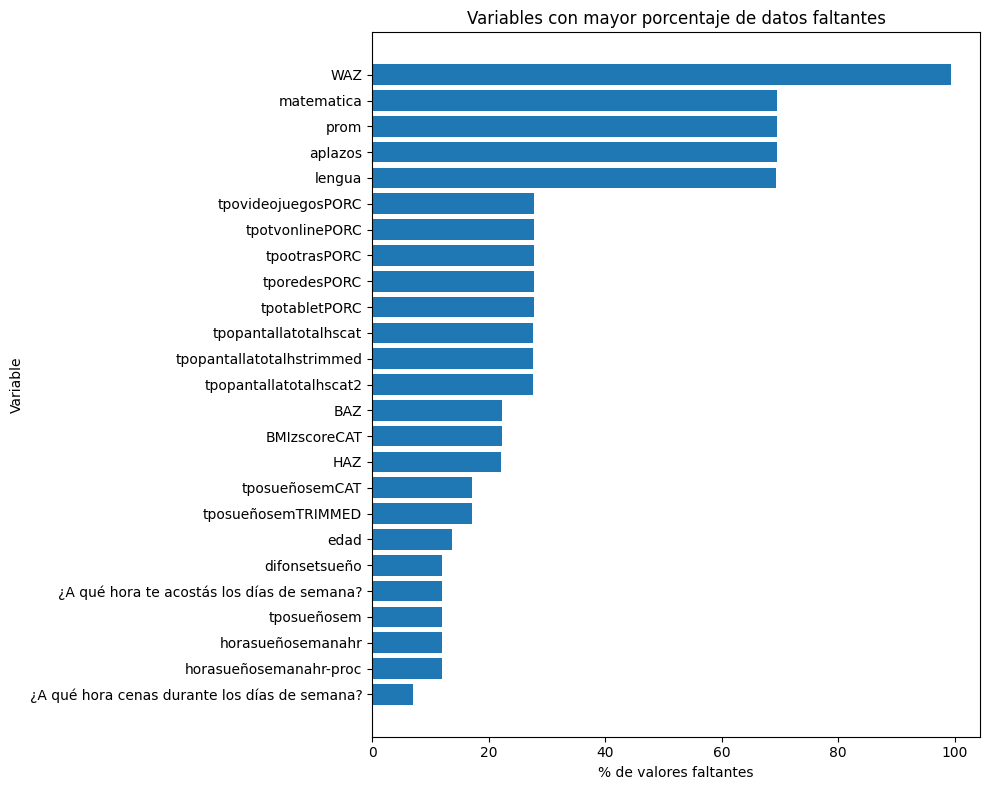

In [12]:
missing = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": df.isna().mean() * 100
}).sort_values("porcentaje", ascending=False)

display(missing.head(30))

# Visualización de las variables con mayor porcentaje de faltantes
top_missing = missing.head(25).sort_values("porcentaje")

plt.figure(figsize=(10, 8))
plt.barh(top_missing.index, top_missing["porcentaje"])
plt.xlabel("% de valores faltantes")
plt.ylabel("Variable")
plt.title("Variables con mayor porcentaje de datos faltantes")
plt.tight_layout()
plt.show()

**Interpretación:**

La presencia de valores faltantes no es homogénea entre las variables. Algunas presentan niveles muy elevados de ausencia, mientras que otras conservan una alta proporción de observaciones disponibles. Por este motivo, no se aplicará una estrategia global de eliminación o imputación, sino que el tratamiento dependerá de la función de cada variable dentro del análisis.

### Criterio de tratamiento de faltantes

Se distingue la función de cada variable:

- **Entradas de clustering:** cinco actividades originales, con validación de dominio y selección de casos completos. En este archivo no presentan faltantes tras validar, por lo que no se imputa ni se excluyen filas adicionales por este motivo.
- **Caracterización:** se mantienen los faltantes, se informa n válido y porcentaje de ausencia por perfil y no se elimina al participante del clustering.
- **Variables no seleccionadas:** su completitud se documenta como parte del EDA; no se aplican eliminaciones globales por un umbral arbitrario de nulos.

No se interpreta un faltante como cero. Los valores invalidados mediante controles de dominio se registran separadamente de los faltantes originales.


## 6.2 Duplicados

In [13]:
duplicados_exactos = df.duplicated().sum()
print("Filas completamente duplicadas:", duplicados_exactos)

for id_col in ["Submission ID", "Código"]:
    if id_col in df.columns:
        dup = df[id_col].duplicated(keep=False)
        print(f"{id_col}: {dup.sum()} registros involucrados en valores duplicados")
        if dup.any():
            display(df.loc[dup, [id_col]].sort_values(id_col).head(20))

Filas completamente duplicadas: 0
Submission ID: 0 registros involucrados en valores duplicados
Código: 2 registros involucrados en valores duplicados


,Código
2573,10 19 48 2 1 IR 0 131004
2574,10 19 48 2 1 IR 0 131004


**Interpretación de duplicados:**

No se detectaron filas completamente duplicadas ni valores repetidos en Submission ID. Se identificaron dos registros que comparten el mismo valor de Código; sin embargo, al no tratarse de filas idénticas, esta repetición no se considerará por sí sola evidencia suficiente para eliminar registros. El identificador se conserva únicamente con fines de trazabilidad y no será utilizado como variable de entrada para el clustering.

## 6.3 Búsqueda de errores, textos especiales e inconsistencias

In [14]:
# Búsqueda de valores especiales o posibles representaciones textuales
# de errores y datos faltantes en las variables del dataset.
errores_busqueda = [
    "#NAME?", "#VALUE!", "#REF!", "#DIV/0!", "#N/A",
    "Sin información", "sin informacion", "inf", "-inf"
]

hallazgos = []

for c in df.columns:
    s = df[c].astype(str)
    for patron in errores_busqueda:
        mask = s.str.contains(re.escape(patron), case=False, na=False)
        if mask.any():
            hallazgos.append({
                "variable": c,
                "patron": patron,
                "cantidad": int(mask.sum())
            })

hallazgos_df = pd.DataFrame(hallazgos)

if len(hallazgos_df):
    display(hallazgos_df.sort_values("cantidad", ascending=False))
else:
    print("No se encontraron los patrones de error buscados en los valores cargados por pandas.")
    print("Nota: si el Excel contiene fórmulas rotas, pandas puede leer el valor almacenado o NaN dependiendo del archivo.")

,variable,patron,cantidad
0,FECHA_NAC_RECOD,Sin información,535
1,FECHA_NAC_RECOD,inf,535


In [15]:
# Infinitos en variables numéricas
num_cols = df.select_dtypes(include=np.number).columns
inf_counts = {}

for c in num_cols:
    n_inf = np.isinf(df[c].to_numpy(dtype=float, na_value=np.nan)).sum()
    if n_inf > 0:
        inf_counts[c] = int(n_inf)

print("Variables con valores infinitos:")
print(inf_counts if inf_counts else "Ninguna")

Variables con valores infinitos:
Ninguna


**Interpretación:**

La búsqueda no detectó valores infinitos en las variables numéricas. Los patrones "Sin información" e "inf" encontrados en FECHA_NAC_RECOD corresponden a representaciones textuales de información faltante o no disponible. Esta variable no será utilizada como entrada para el clustering, por lo que estos valores no afectan directamente la formación de los grupos.

## 6.4 Indicadores de completitud y exclusión

El dataset incluye indicadores construidos durante el procesamiento original. Estos indicadores se analizarán, pero no se utilizarán ciegamente como filtro, ya que nuestro objetivo de clustering puede requerir criterios diferentes del estudio original.

Nota: En los indicadores de completitud, 0 representa un registro incompleto y 1 un registro completo. Los indicadores de exclusión se interpretarán de acuerdo con su definición original.

In [16]:
# Revisión de los indicadores de completitud y exclusión
# incluidos en el procesamiento original del dataset.
cols_indicadores = [
    "datoscompletoDEMOG",
    "datoscompletoSUENO",
    "datoscompletoPANTALLAS",
    "excSUENOpantallas",
    "excluidos",
    "missingnotas",
    "excluFINAL",
]
cols_indicadores = [c for c in cols_indicadores if c in df.columns]

for c in cols_indicadores:
    print(f"\n{c}")
    display(
        df[c]
        .value_counts(dropna=False)
        .rename("cantidad")
        .to_frame()
        .assign(porcentaje=lambda x: x["cantidad"] / len(df) * 100)
    )


datoscompletoDEMOG


,cantidad,porcentaje
datoscompletoDEMOG,,
1,3553,86.342649
0,562,13.657351



datoscompletoSUENO


,cantidad,porcentaje
datoscompletoSUENO,,
1,3220,78.250304
0,895,21.749696



datoscompletoPANTALLAS


...

,cantidad,porcentaje
excluidos,,
0,2449,59.513973
1,1666,40.486027



missingnotas


,cantidad,porcentaje
missingnotas,,
1,2858,69.45322
0,1257,30.54678



excluFINAL


,cantidad,porcentaje
excluFINAL,,
1,3251,79.003645
0,864,20.996355


**Interpretación:**

Estas variables fueron construidas durante el procesamiento original a partir de información disponible en otras variables del dataset y permiten conocer los criterios de completitud y exclusión utilizados en el estudio de origen. Sin embargo, no se utilizarán automáticamente como filtros ni como variables de entrada para el clustering, ya que el presente trabajo persigue un objetivo diferente: identificar perfiles de consumo digital. La inclusión de registros se determinará en función de la disponibilidad de las variables necesarias para cada etapa del análisis.

# 7 Análisis Exploratorio de Datos

## 7.1 Características demográficas

,edad
count,3553.000000
mean,15.600338
std,1.601527
min,12.000000
1%,12.000000
5%,13.000000
25%,14.000000
50%,16.000000
75%,17.000000
95%,18.000000



Distribución de edad:


,cantidad
edad,
12.0,72
13.0,294
14.0,591
15.0,715
16.0,736
17.0,707
18.0,385
19.0,42
20.0,11


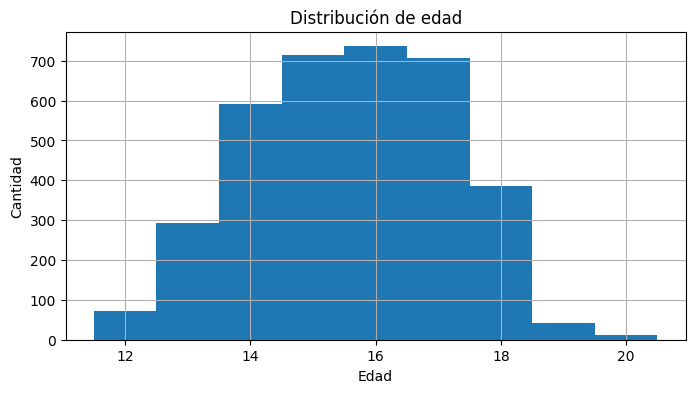

,cantidad
Sexo,
Femenino,2277
Masculino,1838


,cantidad
grado,
1,712
2,761
3,814
4,833
5,745
6,250


In [17]:
# Edad
if "edad" in df.columns:
    display(df["edad"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame())

    print("\nDistribución de edad:")
    display(df["edad"].value_counts(dropna=False).sort_index().rename("cantidad").to_frame())

    plt.figure(figsize=(8, 4))
    df["edad"].dropna().hist(bins=range(
        int(df["edad"].dropna().min()),
        int(df["edad"].dropna().max()) + 2
    ), align="left")
    plt.xlabel("Edad")
    plt.ylabel("Cantidad")
    plt.title("Distribución de edad")
    plt.show()

# Sexo
if "Sexo" in df.columns:
    display(df["Sexo"].value_counts(dropna=False).rename("cantidad").to_frame())

# Grado
if "grado" in df.columns:
    display(df["grado"].value_counts(dropna=False).sort_index().rename("cantidad").to_frame())

In [18]:
if "edad" in df.columns:
    menores_12 = int((df["edad"] < 12).sum())
    entre_12_18 = int(df["edad"].between(12, 18, inclusive="both").sum())
    mayores_18 = int((df["edad"] > 18).sum())
    edad_missing = int(df["edad"].isna().sum())

    display(Markdown(f'''
### Interpretación de edad

- Menores de 12 años: **{menores_12}**
- Entre 12 y 18 años: **{entre_12_18}**
- Mayores de 18 años: **{mayores_18}**
- Edad faltante: **{edad_missing}**

La mayor parte de los registros con edad informada corresponde al rango de 12 a 18 años definido para la población de estudio. Se identifican 53 registros con edades superiores a 18 años y 562 registros sin información de edad. Estos resultados serán considerados posteriormente durante la limpieza, donde se aplicará el criterio poblacional definido para el análisis.
'''))


### Interpretación de edad

- Menores de 12 años: **0**
- Entre 12 y 18 años: **3500**
- Mayores de 18 años: **53**
- Edad faltante: **562**

La mayor parte de los registros con edad informada corresponde al rango de 12 a 18 años definido para la población de estudio. Se identifican 53 registros con edades superiores a 18 años y 562 registros sin información de edad. Estos resultados serán considerados posteriormente durante la limpieza, donde se aplicará el criterio poblacional definido para el análisis.


## 7.2 Consumo digital

## Comparación de variables de consumo digital: originales vs. trimmed

In [19]:
vars_consumo_original = [
    "tpovideojuegoshs",
    "tpojuegotabletcelhs",
    "tporedeshs",
    "tpotvonlinehs",
    "tpootrashs",
    "tpopantallatotalhs",
]

vars_consumo_trimmed = [
    "tpovideojuegoshstrimmed",
    "tpojuegotabletcelhstrimmed",
    "tporedeshstrimmed",
    "tpotvonlinehstrimeed",
    "tpootrashstrimed",
    "tpopantallatotalhstrimmed",
]

vars_consumo_original = [c for c in vars_consumo_original if c in df.columns]
vars_consumo_trimmed = [c for c in vars_consumo_trimmed if c in df.columns]

print("Variables originales:")
print(vars_consumo_original)

print("\nVariables tratadas/trimmed:")
print(vars_consumo_trimmed)

Variables originales:
['tpovideojuegoshs', 'tpojuegotabletcelhs', 'tporedeshs', 'tpotvonlinehs', 'tpootrashs', 'tpopantallatotalhs']

Variables tratadas/trimmed:
['tpovideojuegoshstrimmed', 'tpojuegotabletcelhstrimmed', 'tporedeshstrimmed', 'tpotvonlinehstrimeed', 'tpootrashstrimed', 'tpopantallatotalhstrimmed']


In [20]:
# Información estadística descriptiva detallada, para entender cómo se comporta
# el consumo digital en el grupo de adolescentes
def resumen_numerico(dataframe, columnas):
    columnas = [c for c in columnas if c in dataframe.columns]
    if not columnas:
        return pd.DataFrame()
    return dataframe[columnas].describe(
        percentiles=[.01, .05, .25, .5, .75, .95, .99]
    ).T

display(resumen_numerico(df, vars_consumo_original))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
tpovideojuegoshs,4115.0,1.128919,2.448686,0.0,0.000000,0.000000,0.000000,0.000000,1.333333,5.000000,10.620000,23.833333
tpojuegotabletcelhs,4115.0,2.309599,3.638319,0.0,0.000000,0.000000,0.166667,1.000000,3.000000,9.000000,20.000000,23.833333
tporedeshs,4115.0,4.119603,4.734305,0.0,0.000000,0.166667,1.000000,3.000000,5.000000,14.600000,23.833333,23.833333
tpotvonlinehs,4115.0,3.006278,3.607642,0.0,0.000000,0.000000,1.000000,2.000000,3.500000,9.000000,23.000000,23.833333
tpootrashs,4115.0,1.204536,3.061070,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,5.000000,20.000000,23.833333
tpopantallatotalhs,4115.0,11.768935,11.743242,0.0,1.333333,2.500000,5.166667,8.166666,14.000000,32.883333,61.833333,119.166667


In [21]:
# Resumen comparativo: se reutiliza la función definida en la celda anterior.
display(resumen_numerico(df, vars_consumo_trimmed))


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
tpovideojuegoshstrimmed,4084.0,0.988859,1.823476,0.0,0.0,0.000000,0.000000,0.0,1.166667,5.000000,8.556667,12.500000
tpojuegotabletcelhstrimmed,4001.0,1.844997,2.329956,0.0,0.0,0.000000,0.166667,1.0,3.000000,6.500000,10.000000,12.500000
tporedeshstrimmed,3867.0,3.139686,2.628481,0.0,0.0,0.166667,1.000000,2.5,4.000000,9.000000,11.670000,12.833333
tpotvonlinehstrimeed,3997.0,2.510633,2.110032,0.0,0.0,0.000000,1.000000,2.0,3.000000,6.833333,10.000000,12.500000
tpootrashstrimed,4047.0,0.883206,1.745650,0.0,0.0,0.000000,0.000000,0.0,1.000000,4.500000,9.000000,12.500000
tpopantallatotalhstrimmed,2975.0,6.714846,2.959485,0.0,1.0,2.166667,4.333333,6.5,9.000000,12.000000,12.876667,13.000000


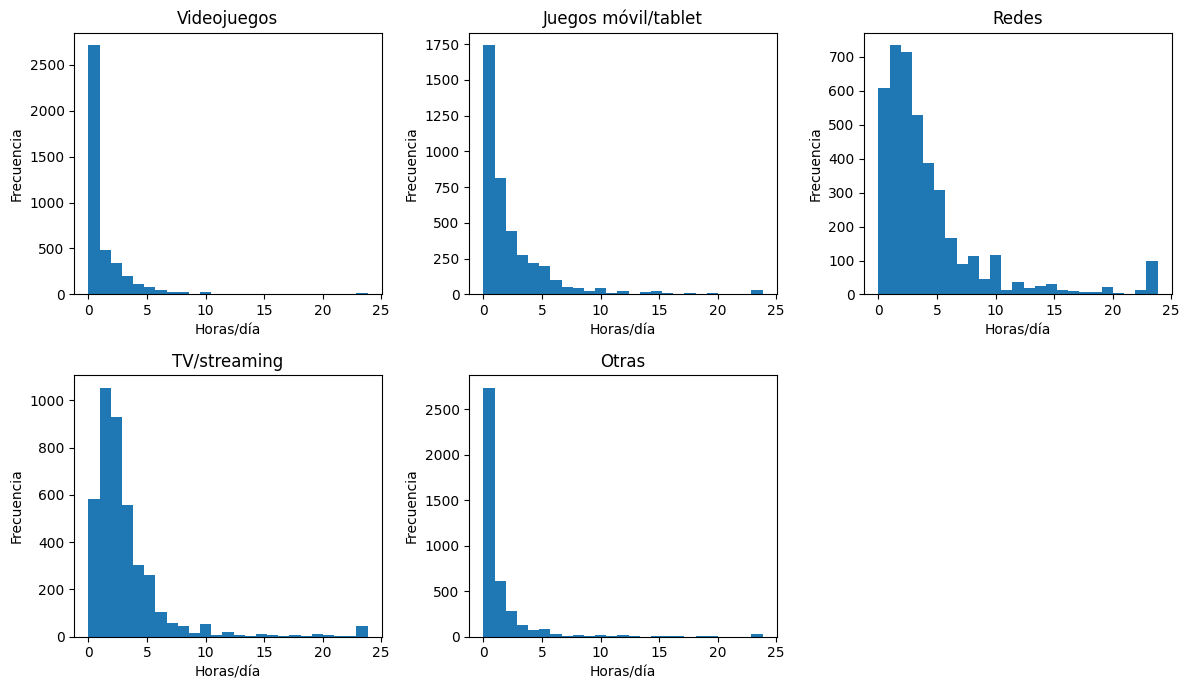

In [22]:
fig,axes=plt.subplots(2,3,figsize=(12,7))
for ax,col,nombre in zip(axes.ravel(),vars_consumo_original[:5],["Videojuegos","Juegos móvil/tablet","Redes","TV/streaming","Otras"]):
    ax.hist(pd.to_numeric(df[col],errors="coerce").dropna(),bins=25)
    ax.set(title=nombre,xlabel="Horas/día",ylabel="Frecuencia")
axes.ravel()[-1].axis("off")
plt.tight_layout();plt.show()


**Interpretación:**

Las distribuciones e histogramas permiten comparar las variables originales con sus versiones `trimmed`. Un rango más acotado no demuestra, por sí solo, que una versión sea más adecuada para el clustering. Los consumos elevados pueden representar perfiles relevantes y no deben descartarse únicamente por ser extremos estadísticos. Se documenta el criterio del estudio de origen y se audita su correspondencia con las columnas del dataset.


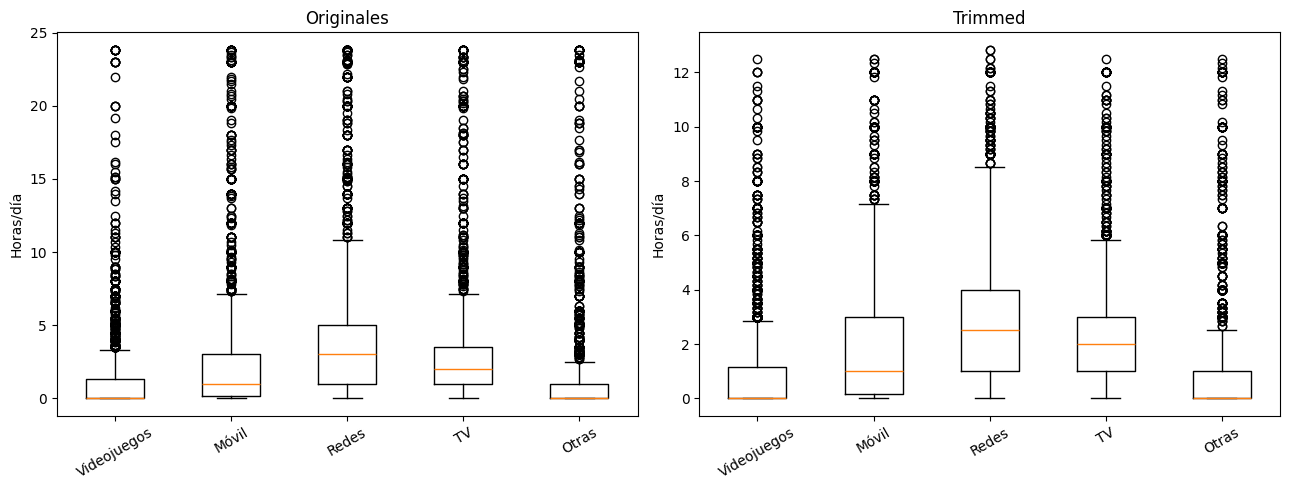

In [23]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,cols,titulo in [(axes[0],vars_consumo_original[:5],"Originales"),(axes[1],vars_consumo_trimmed[:5],"Trimmed")]:
    ax.boxplot([pd.to_numeric(df[c],errors="coerce").dropna() for c in cols],tick_labels=["Videojuegos","Móvil","Redes","TV","Otras"])
    ax.set(title=titulo,ylabel="Horas/día");ax.tick_params(axis="x",rotation=30)
plt.tight_layout();plt.show()


**Conclusión — elección de las variables originales:**

El artículo de origen indica que los tiempos diarios por actividad superiores a 12 horas se trataron como faltantes (*Methods → Measurements*). Es decir: **los valores superiores a 12 horas se trataron como datos faltantes; no se reemplazaron por 12 horas**. La auditoría siguiente comprueba si las cinco versiones `trimmed` del archivo reproducen esa regla; no presupone su resultado ni la extrapola a otras familias.

Para este trabajo se eligen las variables originales de horas por actividad. El objetivo es identificar perfiles de consumo digital, incluyendo usos intensivos; un umbral de 12 horas podría eliminar información relevante o diluirla mediante una imputación posterior. Tener un rango menor no hace que una representación sea automáticamente más adecuada para ese objetivo.

Esta elección no supone aceptar todas las respuestas como válidas: se conservan los tiempos finitos entre 0 y 24 horas por actividad, incluidos los superiores a 12. Se convierten en faltantes los valores negativos, superiores a 24 horas, infinitos o no interpretables como números, registrando el motivo. Estos controles asumen que cada columna mide horas por día, conforme a la descripción del instrumento. No se aplica el límite de 24 horas a la suma de actividades, porque pueden realizarse simultáneamente. Los casos altos dentro del rango se señalan para revisión, sin recortarlos ni eliminarlos por IQR.

Se trata de una decisión propia del presente análisis exploratorio. Durante el modelado se evaluará la influencia de los consumos altos y las diferencias de calidad entre grupos; no se presupone que los valores conservados estén libres de error de autorreporte.

**Fuente:** Pérez-Chada et al. (2023), [Screen use, sleep duration, daytime somnolence, and academic failure in school-aged adolescents](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0281379), sección *Methods → Measurements*. [Dataset de CONICET](https://datosdeinvestigacion.conicet.gov.ar/items/d77da043-7328-4c73-9f0c-e659b0dce258).

**Resultado de la auditoría del archivo:** las cinco versiones `trimmed` presentan respectivamente 1, 3, 6, 1 y 3 discrepancias con la regla estricta de más de 12 horas. En esos casos se conservan tiempos entre 12 y 13 horas. Por lo tanto, la descripción del artículo no reproduce exactamente todas las decisiones del archivo; no se infiere una regla alternativa sin documentación. Esta diferencia refuerza la necesidad de controles explícitos propios sobre las variables originales.


In [24]:
# Auditoría de las versiones trimmed de tiempo diario por actividad.
# Contrasta el archivo con la regla documentada en el artículo: >12 h -> NaN.
# No modifica df ni elimina registros.
pares_consumo = {
    "tpovideojuegoshs": "tpovideojuegoshstrimmed",
    "tpojuegotabletcelhs": "tpojuegotabletcelhstrimmed",
    "tporedeshs": "tporedeshstrimmed",
    "tpotvonlinehs": "tpotvonlinehstrimeed",
    "tpootrashs": "tpootrashstrimed",
}

requeridas = set(pares_consumo) | set(pares_consumo.values())
faltantes = requeridas - set(df.columns)
if faltantes:
    raise ValueError(f"Faltan columnas necesarias para la auditoría: {sorted(faltantes)}")

auditoria_trimmed = []
discrepancias_trimmed = []

for original, trimmed in pares_consumo.items():
    a = pd.to_numeric(df[original], errors="coerce")
    b = pd.to_numeric(df[trimmed], errors="coerce")
    esperado = a.mask(a > 12)
    coincide = pd.Series(
        np.isclose(b.to_numpy(dtype=float), esperado.to_numpy(dtype=float),
                   rtol=0, atol=1e-8, equal_nan=True),
        index=df.index
    )
    iguales = pd.Series(
        np.isclose(a.to_numpy(dtype=float), b.to_numpy(dtype=float),
                   rtol=0, atol=1e-8, equal_nan=True),
        index=df.index
    )
    auditoria_trimmed.append({
        "original": original,
        "trimmed": trimmed,
        "originales_mayores_12h": int((a > 12).sum()),
        "nuevos_nulos": int((a.notna() & b.isna()).sum()),
        "valores_modificados_no_nulos": int((a.notna() & b.notna() & ~iguales).sum()),
        "conversiones_no_numericas_original": int((df[original].notna() & a.isna()).sum()),
        "conversiones_no_numericas_trimmed": int((df[trimmed].notna() & b.isna()).sum()),
        "discrepancias_con_regla_12h": int((~coincide).sum()),
    })
    if (~coincide).any():
        detalle = pd.DataFrame({
            "variable": original, "original": a,
            "trimmed_observado": b, "esperado_regla_12h": esperado
        }).loc[~coincide]
        discrepancias_trimmed.append(detalle)

auditoria_trimmed = pd.DataFrame(auditoria_trimmed)
display(auditoria_trimmed)

if discrepancias_trimmed:
    print("Hay diferencias respecto de la regla de 12 horas. Investigar antes de seleccionar estas versiones.")
    display(pd.concat(discrepancias_trimmed).head(30))
else:
    print("Las cinco versiones coinciden con la regla >12 horas -> faltante en los valores numéricos.")

conversiones = auditoria_trimmed[[
    "conversiones_no_numericas_original", "conversiones_no_numericas_trimmed"
]].to_numpy().sum()
if conversiones:
    print("Atención: hay valores no numéricos convertidos a NaN; revisar antes de concluir.")

# Pérdida conjunta de disponibilidad: no sumar faltantes por columna,
# porque una misma persona puede tener más de una actividad afectada.
originales = df[list(pares_consumo)].apply(pd.to_numeric, errors="coerce")
tratadas = df[list(pares_consumo.values())].apply(pd.to_numeric, errors="coerce")
completos_originales = originales.notna().all(axis=1)
completos_trimmed = tratadas.notna().all(axis=1)
print("Registros auditados:", len(df))
print("Casos completos en las cinco originales:", int(completos_originales.sum()))
print("Casos completos en las cinco trimmed:", int(completos_trimmed.sum()))
print("Casos completos originales que dejan de serlo:",
      int((completos_originales & ~completos_trimmed).sum()))


,original,trimmed,originales_mayores_12h,nuevos_nulos,valores_modificados_no_nulos,conversiones_no_numericas_original,conversiones_no_numericas_trimmed,discrepancias_con_regla_12h
0,tpovideojuegoshs,tpovideojuegoshstrimmed,32,31,0,0,0,1
1,tpojuegotabletcelhs,tpojuegotabletcelhstrimmed,117,114,0,0,0,3
2,tporedeshs,tporedeshstrimmed,254,248,0,0,0,6
3,tpotvonlinehs,tpotvonlinehstrimeed,119,118,0,0,0,1
4,tpootrashs,tpootrashstrimed,71,68,0,0,0,3


Hay diferencias respecto de la regla de 12 horas. Investigar antes de seleccionar estas versiones.


,variable,original,trimmed_observado,esperado_regla_12h
3752,tpovideojuegoshs,12.500000,12.500000,NaN
490,tpojuegotabletcelhs,12.333333,12.333333,NaN
1427,tpojuegotabletcelhs,12.500000,12.500000,NaN
2382,tpojuegotabletcelhs,12.500000,12.500000,NaN
831,tporedeshs,12.500000,12.500000,NaN
1647,tporedeshs,12.833333,12.833333,NaN
1817,tporedeshs,12.833333,12.833333,NaN
2389,tporedeshs,12.500000,12.500000,NaN
2489,tporedeshs,12.166667,12.166667,NaN
3556,tporedeshs,12.166667,12.166667,NaN


Registros auditados: 4115
Casos completos en las cinco originales: 4115
Casos completos en las cinco trimmed: 3744
Casos completos originales que dejan de serlo: 371


### 7.2.1 Auditoría de las duraciones y los extremos

Se reconstruyen horas desde las respuestas originales de formato `datetime.time`, duración o texto HH:MM[:SS], y se comparan con las variables numéricas con tolerancia de 10⁻⁶ horas. Los formatos no reconocidos se registran sin inventar unidades. También se cuenta la concentración en 23:50 y se señalan consumos superiores a 12 horas o sumas superiores a 24.

Estas banderas no eliminan casos automáticamente: puede haber simultaneidad. Una conversión consistente descarta una discrepancia aritmética, pero no demuestra plausibilidad del autorreporte ni aclara posibles opciones/códigos de la encuesta. No se interpreta 23:50 como ausencia sin documentación.

La conversión se audita sobre el archivo original completo. Las banderas de extremos de la población final se calculan después de la limpieza, en el apartado 12.2.


In [25]:
RESPUESTAS = {
    "tpovideojuegoshs": "Videojuegos en computadora o consolas (PlayStation, Xbox, WII, etc).",
    "tpojuegotabletcelhs": "Juegos en tablet y/o teléfono celular.",
    "tporedeshs": "Uso de redes sociales (Facebook, Instagram, Twitter, Snapchat, etc).",
    "tpotvonlinehs": "Mirar televisión o contenido online (TV, Netflix, YouTube, etc).",
    "tpootrashs": "Otras actividades frente a una pantalla.",
}


def horas_respuesta(valor):
    if pd.isna(valor):
        return np.nan
    if isinstance(valor, datetime.time):
        return valor.hour + valor.minute / 60 + valor.second / 3600
    if isinstance(valor, (pd.Timedelta, datetime.timedelta)):
        return valor.total_seconds() / 3600
    if isinstance(valor, str):
        m = re.fullmatch(r"(\d{1,3}):(\d{2})(?::(\d{2}))?", valor.strip())
        if m and int(m[2]) < 60 and int(m[3] or 0) < 60:
            return int(m[1]) + int(m[2]) / 60 + int(m[3] or 0) / 3600
    return np.nan


filas_conversion, detalles_conversion = [], []
for variable, respuesta in RESPUESTAS.items():
    raw = df_original[respuesta]
    reconstruido = raw.map(horas_respuesta)
    registrado = pd.to_numeric(df_original[variable], errors="coerce")
    comparable = reconstruido.notna() & registrado.notna()
    dif = comparable & ~np.isclose(reconstruido, registrado, atol=1e-6, rtol=0, equal_nan=True)
    no_interpretado = raw.notna() & reconstruido.isna()
    filas_conversion.append({
        "variable": variable, "n": len(raw), "comparables": int(comparable.sum()),
        "no_interpretados": int(no_interpretado.sum()), "discrepancias": int(dif.sum()),
        "max_diferencia_horas": (reconstruido - registrado).abs().max(),
        "mayor12_n": int(registrado.gt(12).sum()),
        "respuesta_23_50_n": int(np.isclose(reconstruido, 23 + 50 / 60, atol=1e-6, rtol=0).sum()),
    })
    for indice in raw.index[dif | no_interpretado]:
        detalles_conversion.append({"fila_origen": indice, "variable": variable,
            "respuesta": str(raw.loc[indice]), "reconstruido": reconstruido.loc[indice],
            "registrado": registrado.loc[indice]})
auditoria_conversion = pd.DataFrame(filas_conversion)
detalle_conversion = pd.DataFrame(detalles_conversion, columns=[
    "fila_origen", "variable", "respuesta", "reconstruido", "registrado"])
display(auditoria_conversion)


,variable,n,comparables,no_interpretados,discrepancias,max_diferencia_horas,mayor12_n,respuesta_23_50_n
0,tpovideojuegoshs,4115,4115,0,0,1.066667e-07,32,8
1,tpojuegotabletcelhs,4115,4115,0,0,1.066667e-07,117,14
2,tporedeshs,4115,4115,0,0,1.066667e-07,254,43
3,tpotvonlinehs,4115,4115,0,0,1.066667e-07,119,18
4,tpootrashs,4115,4115,0,0,1.066667e-07,71,16


## 7.3 Validación del tiempo total de pantalla

Se comprobará si el tiempo total de pantalla coincide con la suma de sus componentes. Esta validación permite detectar inconsistencias y decidir si conviene utilizar el total provisto, reconstruirlo o trabajar directamente con los componentes.

In [26]:
componentes = [
    "tpovideojuegoshs",
    "tpojuegotabletcelhs",
    "tporedeshs",
    "tpotvonlinehs",
    "tpootrashs",
]
componentes = [c for c in componentes if c in df.columns]

if "tpopantallatotalhs" in df.columns and len(componentes) >= 2:
    suma_componentes = df[componentes].sum(axis=1, min_count=len(componentes))
    diferencia = df["tpopantallatotalhs"] - suma_componentes

    validacion_total = pd.DataFrame({
        "total_reportado": df["tpopantallatotalhs"],
        "suma_componentes": suma_componentes,
        "diferencia": diferencia
    })

    tolerancia = 0.05

    print("Resumen de la diferencia total - suma de componentes:")
    display(diferencia.describe(percentiles=[.01, .05, .5, .95, .99]).to_frame())

    consistentes = diferencia.abs() <= tolerancia
    n_validos = diferencia.notna().sum()
    n_consistentes = consistentes.sum()

    if n_validos:
        print(f"Registros comparables: {n_validos}")
        print(f"Consistentes dentro de ±{tolerancia}: {n_consistentes} ({n_consistentes/n_validos*100:.2f}%)")

    print("\nCasos con mayores discrepancias:")
    display(validacion_total.loc[diferencia.abs().sort_values(ascending=False).head(15).index])

Resumen de la diferencia total - suma de componentes:


,0
count,4115.0
mean,0.0
std,0.0
min,0.0
1%,0.0
5%,0.0
50%,0.0
95%,0.0
99%,0.0
max,0.0


Registros comparables: 4115
Consistentes dentro de ±0.05: 4115 (100.00%)

Casos con mayores discrepancias:


,total_reportado,suma_componentes,diferencia
4114,8.833333,8.833333,0.0
0,11.000000,11.000000,0.0
1,10.500000,10.500000,0.0
4098,5.666667,5.666667,0.0
4097,15.500000,15.500000,0.0
4096,4.000000,4.000000,0.0
4095,6.000000,6.000000,0.0
4094,5.666667,5.666667,0.0
4093,4.500000,4.500000,0.0
4092,2.500000,2.500000,0.0


**Interpretación:**

La validación muestra que, para los 4.115 registros analizados, el tiempo total de pantalla coincide exactamente con la suma de sus componentes, obteniéndose una consistencia del 100 %. Por lo tanto, la variable de tiempo total de pantalla representa información agregada que ya se encuentra contenida en las variables específicas de consumo digital. Para la construcción de los clusters se priorizarán los componentes individuales, ya que permiten conservar información sobre la composición del consumo y evitar incorporar simultáneamente una variable total junto con las variables que la conforman.

## 7.4 Composición porcentual del consumo digital

In [27]:
vars_porcentajes = [
    "tpovideojuegosPORC",
    "tpotabletPORC",
    "tporedesPORC",
    "tpotvonlinePORC",
    "tpootrasPORC",
]
vars_porcentajes = [c for c in vars_porcentajes if c in df.columns]

if vars_porcentajes:
    display(resumen_numerico(df, vars_porcentajes))

    suma_porc = df[vars_porcentajes].sum(axis=1, min_count=len(vars_porcentajes))
    print("\nResumen de la suma de porcentajes:")
    display(suma_porc.describe(percentiles=[.01, .05, .5, .95, .99]).to_frame())

    problemas_porc = pd.DataFrame({
        "suma_porcentajes": suma_porc,
        "menor_que_99": suma_porc < 99,
        "mayor_que_101": suma_porc > 101,
    })

    print("Cantidad con suma < 99:", problemas_porc["menor_que_99"].sum())
    print("Cantidad con suma > 101:", problemas_porc["mayor_que_101"].sum())

    for c in vars_porcentajes:
        print(
            f"{c}: negativos={(df[c] < 0).sum()}, "
            f">100={(df[c] > 100).sum()}, "
            f"missing={df[c].isna().sum()}"
        )

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
tpovideojuegosPORC,2969.0,9.374958,16.114084,0.0,0.0,0.000000,0.000000,0.000000,15.254237,45.953177,66.666664,89.189188
tpotabletPORC,2969.0,17.604126,17.653831,0.0,0.0,0.000000,0.000000,13.043476,28.571427,50.000000,67.047622,100.000000
tporedesPORC,2969.0,36.675647,22.428659,0.0,0.0,2.873705,19.999998,33.333334,50.000000,77.777776,94.897243,100.000000
tpotvonlinePORC,2969.0,29.400741,18.280185,0.0,0.0,0.000000,16.666664,27.272727,40.000000,62.500000,80.000002,100.000000
tpootrasPORC,2969.0,6.944527,12.242976,0.0,0.0,0.000000,0.000000,0.000000,10.526316,32.851027,53.721212,100.000000



Resumen de la suma de porcentajes:


,0
count,2.969000e+03
mean,1.000000e+02
std,9.718136e-15
min,1.000000e+02
1%,1.000000e+02
5%,1.000000e+02
50%,1.000000e+02
95%,1.000000e+02
99%,1.000000e+02
max,1.000000e+02


Cantidad con suma < 99: 0
Cantidad con suma > 101: 0
tpovideojuegosPORC: negativos=0, >100=0, missing=1146
tpotabletPORC: negativos=0, >100=0, missing=1146
tporedesPORC: negativos=0, >100=0, missing=1146
tpotvonlinePORC: negativos=0, >100=0, missing=1146
tpootrasPORC: negativos=0, >100=0, missing=1146


### Consideración metodológica sobre porcentajes

Las proporciones representan una composición y presentan dependencia matemática entre sí. Además, son una representación derivada del consumo. Se seleccionan las cinco variables originales de horas por actividad para conservar tanto la intensidad como su distribución entre actividades, sin incorporar simultáneamente porcentajes, total y componentes al clustering. La completitud se consulta en las tablas calculadas, sin trasladar cifras de las versiones `trimmed` a las originales.


## 7.5 Frecuencia de uso de dispositivos

In [28]:
vars_dispositivos_raw = [
    "PC o Laptop", "Teléfono celular 2", "Tablet",
    "Consola de juegos", "TV o Smart TV"
]

vars_dispositivos_trimmed = [
    "cantdiascompustrimmed",
    "cantdiascelulartrimmed",
    "cantdiastablettrimmed",
    "cantdiasconsolajuegostrimmed",
    "cantdiastvtrimmed",
]

vars_dispositivos_bin = [
    "cantdiascompus01",
    "cantdiascelular01",
    "cantdiastablet01",
    "cantdiasconsolajuegos01",
    "cantdiastv01",
]

for grupo, columnas in {
    "Originales": vars_dispositivos_raw,
    "Tratadas": vars_dispositivos_trimmed,
    "Binarias": vars_dispositivos_bin
}.items():
    disponibles = [c for c in columnas if c in df.columns]
    print(f"\n{grupo}:")
    if disponibles:
        display(resumen_numerico(df, disponibles))


Originales:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
PC o Laptop,4115.0,0.915674,1.792854,0.0,0.0,0.0,0.0,0.0,1.0,5.0,7.0,9.0
Teléfono celular 2,4115.0,5.948967,2.126601,0.0,0.0,1.0,5.0,7.0,7.0,8.0,9.0,9.0
Tablet,4115.0,0.379830,1.295380,0.0,0.0,0.0,0.0,0.0,0.0,3.0,7.0,9.0
Consola de juegos,4115.0,0.754800,1.693994,0.0,0.0,0.0,0.0,0.0,0.0,5.0,7.0,9.0
TV o Smart TV,4115.0,2.715917,2.639262,0.0,0.0,0.0,0.0,2.0,5.0,7.0,9.0,9.0



Tratadas:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
cantdiascompustrimmed,4097.0,0.880644,1.716805,0.0,0.0,0.0,0.0,0.0,1.0,5.0,7.0,7.0
cantdiascelulartrimmed,3907.0,5.799335,2.076166,0.0,0.0,1.0,5.0,7.0,7.0,7.0,7.0,7.0
cantdiastablettrimmed,4105.0,0.359562,1.229836,0.0,0.0,0.0,0.0,0.0,0.0,3.0,7.0,7.0
cantdiasconsolajuegostrimmed,4089.0,0.704084,1.574623,0.0,0.0,0.0,0.0,0.0,0.0,5.0,7.0,7.0
cantdiastvtrimmed,4056.0,2.627959,2.554346,0.0,0.0,0.0,0.0,2.0,5.0,7.0,7.0,7.0



Binarias:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
cantdiascompus01,4115.0,0.312758,0.463673,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0
cantdiascelular01,4115.0,0.971810,0.165534,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
cantdiastablet01,4115.0,0.116889,0.321328,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
cantdiasconsolajuegos01,4115.0,0.236695,0.425105,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
cantdiastv01,4115.0,0.683597,0.465129,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0


In [29]:
# Comparación verificable de frecuencias originales y trimmed.
# Auditoría sobre df completo, antes del filtro etario.
pares_frecuencia = {
    "PC o Laptop": "cantdiascompustrimmed",
    "Teléfono celular 2": "cantdiascelulartrimmed",
    "Tablet": "cantdiastablettrimmed",
    "Consola de juegos": "cantdiasconsolajuegostrimmed",
    "TV o Smart TV": "cantdiastvtrimmed",
}
filas_frecuencia = []
for original, trimmed in pares_frecuencia.items():
    a = pd.to_numeric(df[original], errors="coerce")
    b = pd.to_numeric(df[trimmed], errors="coerce")
    valido = a.between(0, 7) & a.mod(1).eq(0)
    esperado = a.where(valido)
    coincide = np.isclose(esperado, b, rtol=0, atol=1e-8, equal_nan=True)
    filas_frecuencia.append({
        "original": original,
        "trimmed": trimmed,
        "registros_auditados": len(df),
        "fuera_dominio_0_7": int((a.notna() & ~valido).sum()),
        "no_numericos_original": int((df[original].notna() & a.isna()).sum()),
        "no_numericos_trimmed": int((df[trimmed].notna() & b.isna()).sum()),
        "discrepancias_con_validacion_propia": int((~coincide).sum()),
    })
auditoria_frecuencia = pd.DataFrame(filas_frecuencia)
display(auditoria_frecuencia)
print("Esta comparación muestra equivalencia observada; no demuestra qué código usaron los autores.")


,original,trimmed,registros_auditados,fuera_dominio_0_7,no_numericos_original,no_numericos_trimmed,discrepancias_con_validacion_propia
0,PC o Laptop,cantdiascompustrimmed,4115,18,0,0,0
1,Teléfono celular 2,cantdiascelulartrimmed,4115,208,0,0,0
2,Tablet,cantdiastablettrimmed,4115,10,0,0,0
3,Consola de juegos,cantdiasconsolajuegostrimmed,4115,26,0,0,0
4,TV o Smart TV,cantdiastvtrimmed,4115,59,0,0,0


Esta comparación muestra equivalencia observada; no demuestra qué código usaron los autores.


**Conclusión — frecuencia de dispositivos:**

Se seleccionan las frecuencias originales (`PC o Laptop`, `Teléfono celular 2`, `Tablet`, `Consola de juegos`, `TV o Smart TV`) y se aplica una validación propia de días enteros entre 0 y 7. Según el instrumento del artículo, estas variables miden días por semana de uso de dispositivos en la hora previa a dormir; no representan el uso general durante todo el día. El cero se conserva como ausencia de uso en ese contexto. Las representaciones binarias pierden el detalle de frecuencia y no se incorporan simultáneamente.

La auditoría de los 4.115 registros identifica, respectivamente, 18, 208, 10, 26 y 59 valores fuera del dominio semanal. Al convertirlos en faltantes y conservar los valores válidos, el resultado coincide exactamente con las cinco versiones `trimmed`: no hay discrepancias. Se trata de equivalencia observada en este archivo, no de evidencia sobre el código o la intención exacta de los autores.

Por lo tanto, estas `trimmed` no presentan el mismo problema observado con el umbral de 12 horas de consumo: los valores 8 y 9 no representan una cantidad válida de días en una semana. Sin un diccionario que les asigne otro significado, se tratan como respuestas inválidas o códigos no interpretados; no se recortan a 7 ni se les atribuye una categoría. Se parte de las originales para mantener trazabilidad y una regla reproducible propia; en esta familia, esa decisión no recupera información válida adicional frente a las `trimmed`.

Las cantidades anteriores corresponden al dataset completo. Luego del filtro etario, la tabla de validación de la sección 11 informa los valores afectados en la población conservada. Las frecuencias se reservan para caracterización: sus faltantes no excluyen participantes de la matriz principal de clustering.

En consecuencia, se modifica la selección inicialmente propuesta: se utilizan las variables originales con una validación explícita del dominio de días enteros de 0 a 7. El resultado coincide con las versiones `trimmed`, por lo que no se conserva información adicional válida al elegir las originales. Estas frecuencias se utilizarán únicamente para caracterizar los clusters, sin intervenir en su formación.

**Fuente del significado y unidad:** [Pérez-Chada et al. (2023), Methods → Measurements](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0281379). La equivalencia entre columnas se verifica con el Excel en la celda precedente.


## 7.6 Uso de pantallas cerca del horario de dormir

In [30]:
# Auditoría empírica del significado de los indicadores del archivo.
# El cero no equivale necesariamente a ausencia de uso.
vars_bedtime = ["WATCHTVbedtime7D01", "COMPUbedtime1D01", "COMPUbedtime2D01"]
definiciones_contexto = {
    "WATCHTVbedtime7D01": ("TV o Smart TV", 7),
    "COMPUbedtime1D01": ("PC o Laptop", 1),
    "COMPUbedtime2D01": ("PC o Laptop", 2),
}
for indicador, (frecuencia, dias) in definiciones_contexto.items():
    print(f"{indicador}: contraste con {frecuencia} == {dias} días")
    display(pd.crosstab(df[frecuencia], df[indicador], dropna=False))
    esperado = df[frecuencia].eq(dias).astype(int)
    print("Discrepancias con esa igualdad:", int(df[indicador].ne(esperado).sum()))


WATCHTVbedtime7D01: contraste con TV o Smart TV == 7 días


WATCHTVbedtime7D01,0,1
TV o Smart TV,,
0,1302,0
1,445,0
2,552,0
3,419,0
4,239,0
5,359,0
6,78,0
7,0,662
8,14,0


Discrepancias con esa igualdad: 0
COMPUbedtime1D01: contraste con PC o Laptop == 1 días


COMPUbedtime1D01,0,1
PC o Laptop,,
0,2828,0
1,0,411
2,323,0
3,185,0
4,72,0
5,101,0
6,36,0
7,141,0
8,2,0


Discrepancias con esa igualdad: 0
COMPUbedtime2D01: contraste con PC o Laptop == 2 días


COMPUbedtime2D01,0,1
PC o Laptop,,
0,2828,0
1,411,0
2,0,323
3,185,0
4,72,0
5,101,0
6,36,0
7,141,0
8,2,0


Discrepancias con esa igualdad: 0


**Interpretación corregida:**

La comparación de columnas muestra que `WATCHTVbedtime7D01 = 1` identifica exactamente 7 días de TV cerca de dormir; `COMPUbedtime1D01 = 1` identifica exactamente 1 día de computadora y `COMPUbedtime2D01 = 1`, exactamente 2 días. El valor 0 representa no pertenecer a esa categoría: no puede interpretarse como ausencia general de uso. Estas correspondencias son verificaciones empíricas del archivo, no supuestos por el sufijo del nombre.

Se conservan únicamente para caracterización y no ingresan a K-Means. Si la frecuencia original queda invalidada por estar fuera de 0 a 7, el indicador derivado tampoco se utiliza en su resumen auxiliar. La frecuencia validada original es la referencia principal para describir estos hábitos.


## 7.7 Sueño

In [31]:
vars_sueno = [
    "dursiestasemanahs",
    "¿Cuánto tiempo de pantalla (dispositivos electrónicos) utilizas antes de dormirte los días de semana?",
    "horacenahr",
    "horasueñosemanahr-proc",
    "horasueñosemanahr",
    "¿Cuánto tiempo en Minutos tardas en dormirte?",
    "horalevantarsesemanahr",
    "tposueñosem",
    "tposueñosemTRIMMED",
    "horaacostarfsemanahr",
    "horalevantarsefsemanahr-proc",
    "tpofsueñosem",
    "tposueñofsemTRIMMED",
    "difonsetsueño",
]
vars_sueno = [c for c in vars_sueno if c in df.columns]

display(resumen_numerico(df, vars_sueno))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
dursiestasemanahs,4115.0,1.317375,2.102711,0.000000,0.000000e+00,0.000000,0.000000,0.166667,2.000000,5.000000,8.833333,23.833333
¿Cuánto tiempo de pantalla (dispositivos electrónicos) utilizas antes de dormirte los días de semana?,4115.0,1.146497,2.431514,0.000000,0.000000e+00,0.000000,0.000000,0.000000,1.500000,5.000000,11.930000,23.833333
horacenahr,3826.0,21.510716,0.937604,19.500000,1.950000e+01,20.500000,20.500000,21.500000,22.500000,23.500000,23.500000,24.500000
horasueñosemanahr-proc,3624.0,21.662804,3.288331,13.500000,1.350000e+01,13.500000,21.500000,22.500000,23.500000,24.500000,24.500000,24.500000
horasueñosemanahr,3624.0,23.477373,1.437457,19.500000,2.050000e+01,21.500000,22.500000,23.500000,23.500000,26.500000,27.500000,30.500000
¿Cuánto tiempo en Minutos tardas en dormirte?,4115.0,22.369016,36.071497,0.000000,1.000000e+00,3.000000,10.000000,15.000000,30.000000,60.000000,128.600000,999.000000
horalevantarsesemanahr,4115.0,6.710288,1.024273,0.000000,5.000000e+00,5.833333,6.333333,6.666667,7.000000,7.550000,10.500000,23.833333
tposueñosem,3624.0,6.851534,1.770053,-10.150000,1.500000e+00,3.833333,6.166667,7.000000,7.833333,8.950000,10.730833,24.000000
tposueñosemTRIMMED,3411.0,7.057864,1.230224,4.000000,4.166667e+00,4.833333,6.333333,7.083333,7.833333,8.916667,10.166667,11.883333
horaacostarfsemanahr,4115.0,25.469907,2.253659,19.000000,1.916667e+01,22.000000,23.833333,25.500000,27.000000,29.500000,30.310000,30.833333


In [32]:
# Comparar variables de duración de sueño originales y trimmed
pares_trimmed_sueno = [
    ("tposueñosem", "tposueñosemTRIMMED"),
    ("tpofsueñosem", "tposueñofsemTRIMMED"),
]

for original, trimmed in pares_trimmed_sueno:
    if original in df.columns and trimmed in df.columns:
        print(f"\n{original} vs {trimmed}")
        comparacion = pd.DataFrame({
            original: df[original],
            trimmed: df[trimmed],
        })
        print("Original:")
        display(df[original].describe(percentiles=[.01,.05,.5,.95,.99]).to_frame())
        print("Trimmed:")
        display(df[trimmed].describe(percentiles=[.01,.05,.5,.95,.99]).to_frame())
        print("Registros donde trimmed es NaN pero original no:",
              (df[trimmed].isna() & df[original].notna()).sum())


tposueñosem vs tposueñosemTRIMMED
Original:


,tposueñosem
count,3624.000000
mean,6.851534
std,1.770053
min,-10.150000
1%,1.500000
5%,3.833333
50%,7.000000
95%,8.950000
99%,10.730833
max,24.000000


Trimmed:


,tposueñosemTRIMMED
count,3411.000000
mean,7.057864
std,1.230224
min,4.000000
1%,4.166667
5%,4.833333
50%,7.083333
95%,8.916667
99%,10.166667
max,11.883333


Registros donde trimmed es NaN pero original no: 213

tpofsueñosem vs tposueñofsemTRIMMED
Original:


,tpofsueñosem
count,4115.000000
mean,9.176063
std,3.136769
min,-5.333333
1%,-2.500000
5%,4.783333
50%,9.333333
95%,13.000000
99%,18.000000
max,24.000000


Trimmed:


,tposueñofsemTRIMMED
count,3864.000000
mean,9.291667
std,2.011884
min,1.000000
1%,3.876667
5%,6.000000
50%,9.500000
95%,12.500000
99%,13.500000
max,14.000000


Registros donde trimmed es NaN pero original no: 251


**Interpretación — duración del sueño:**

La comparación con `TRIMMED` se conserva como diagnóstico del procesamiento previo, pero se seleccionan `tposueñosem` y `tpofsueñosem`, las duraciones originales, para caracterizar los perfiles. No se asume que la transformación de sueño sea la misma que la de consumo digital.

Las duraciones negativas, superiores a 24 horas o no finitas se tratarán como faltantes mediante una regla explícita. El cero se conserva y se señala para revisión: aunque pertenece al rango aritmético, no se confirma por ello su plausibilidad clínica. No se reconstruyen horarios ni se imputan duraciones sin información suficiente. Estas variables se reservan para caracterización y no intervienen en la formación de los clusters.


## 7.8 Somnolencia / PDSS

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Resultado,4115.0,18.653220,5.172807,2.0,7.0,10.0,15.0,19.0,22.0,27.0,29.0,32.0
somno01pdss,4115.0,0.719320,0.449386,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
problemasatencionrecod,4115.0,2.173269,1.044403,0.0,0.0,0.0,1.0,2.0,3.0,4.0,4.0,4.0
¿Con qué frecuencia te quedás dormido/a o te da sueño mientras hacés la tarea?,4115.0,1.406561,1.251817,0.0,0.0,0.0,0.0,1.0,2.0,4.0,4.0,4.0
¿Estás atento/a o alerta en clase?,4115.0,3.019927,0.843397,0.0,0.0,1.0,3.0,3.0,4.0,4.0,4.0,4.0
¿Con qué frecuencia te sentís cansado y de mal humor durante el día?,4115.0,2.147995,1.084302,0.0,0.0,0.0,1.0,2.0,3.0,4.0,4.0,4.0
¿Te cuesta levantarte de la cama a la mañana?,4115.0,2.906197,1.280894,0.0,0.0,0.0,2.0,3.0,4.0,4.0,4.0,4.0
¿Te volvés a quedar dormido/a después de que te despertaron a la mañana?,4115.0,1.807776,1.471736,0.0,0.0,0.0,0.0,2.0,3.0,4.0,4.0,4.0
¿Necesitás que alguien te despierte por la mañana?,4115.0,2.324423,1.680907,0.0,0.0,0.0,0.0,3.0,4.0,4.0,4.0,4.0
¿Con qué frecuencia sentís que necesitás dormir más tiempo?,4115.0,2.867072,1.116270,0.0,0.0,1.0,2.0,3.0,4.0,4.0,4.0,4.0


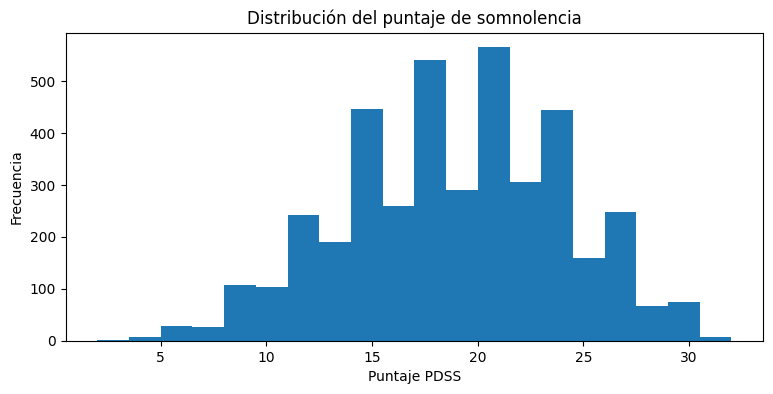

PDSS según indicador binario:


,count,mean,std,min,25%,50%,75%,max
somno01pdss,,,,,,,,
0,1155.0,12.234632,2.528420,2.0,11.0,13.0,14.0,15.0
1,2960.0,21.157770,3.514722,16.0,18.0,21.0,24.0,32.0


In [33]:
vars_pdss = [
    "Resultado",
    "somno01pdss",
    "problemasatencionrecod",
    "¿Con qué frecuencia te quedás dormido/a o te da sueño mientras hacés la tarea?",
    "¿Estás atento/a o alerta en clase?",
    "¿Con qué frecuencia te sentís cansado y de mal humor durante el día?",
    "¿Te cuesta levantarte de la cama a la mañana?",
    "¿Te volvés a quedar dormido/a después de que te despertaron a la mañana?",
    "¿Necesitás que alguien te despierte por la mañana?",
    "¿Con qué frecuencia sentís que necesitás dormir más tiempo?",
]
vars_pdss = [c for c in vars_pdss if c in df.columns]

display(resumen_numerico(df, vars_pdss))

if "Resultado" in df.columns:
    plt.figure(figsize=(9, 4))
    plt.hist(df["Resultado"].dropna(), bins=20)
    plt.xlabel("Puntaje PDSS")
    plt.ylabel("Frecuencia")
    plt.title("Distribución del puntaje de somnolencia")
    plt.show()

if "Resultado" in df.columns and "somno01pdss" in df.columns:
    print("PDSS según indicador binario:")
    display(df.groupby("somno01pdss")["Resultado"].describe())

**Interpretación:**

El puntaje de somnolencia (Resultado) presenta valores entre 2 y 32 puntos, con una mediana de 19. El indicador binario somno01pdss divide los registros en dos grupos claramente diferenciados: los casos con valor 0 presentan puntajes de hasta 15, mientras que los casos con valor 1 presentan puntajes desde 16 en adelante. Esto indica que somno01pdss corresponde a una recodificación del puntaje PDSS utilizando un punto de corte entre ambos valores.


En el dataset, aproximadamente el 71,9 % de los registros pertenece a la categoría somno01pdss = 1, mientras que el 28,1 % corresponde a la categoría 0. Estas variables no se utilizarán para construir los clusters, ya que el agrupamiento estará basado en los patrones de consumo digital. Se conservarán para la caracterización posterior de los grupos, permitiendo analizar si los perfiles identificados presentan diferencias en sus niveles de somnolencia diurna.

## 7.9 Rendimiento académico

In [34]:
vars_academicas = [
    "lengua", "matematica", "prom", "aplazos", "missingnotas"
]
vars_academicas = [c for c in vars_academicas if c in df.columns]

display(resumen_numerico(df, vars_academicas))

for c in vars_academicas:
    print(f"{c}: missing = {df[c].isna().sum()} ({df[c].isna().mean()*100:.2f}%)")

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
lengua,1261.0,7.439453,1.457938,1.0,4.0,5.0,6.66,8.0,8.5,10.0,10.00,10.0
matematica,1257.0,7.175123,1.804322,1.0,2.0,4.0,6.00,7.0,9.0,10.0,10.00,10.0
prom,1257.0,7.308385,1.440699,2.0,3.5,4.5,6.50,7.5,8.5,9.5,9.72,10.0
aplazos,1257.0,0.430390,0.495328,0.0,0.0,0.0,0.00,0.0,1.0,1.0,1.00,1.0
missingnotas,4115.0,0.694532,0.460661,0.0,0.0,0.0,0.00,1.0,1.0,1.0,1.00,1.0


lengua: missing = 2854 (69.36%)
matematica: missing = 2858 (69.45%)
prom: missing = 2858 (69.45%)
aplazos: missing = 2858 (69.45%)
missingnotas: missing = 0 (0.00%)


### Interpretación metodológica del rendimiento académico

Las variables académicas se consideran variables de caracterización y no variables principales para formar los clusters de consumo digital. Dado que aproximadamente el 69 % de los registros no dispone de calificaciones académicas, su ausencia no debería excluir automáticamente a un adolescente del clustering si cuenta con información suficiente sobre comportamiento digital. Estas variables podrán utilizarse posteriormente para explorar posibles diferencias de rendimiento académico entre los perfiles obtenidos, considerando la disponibilidad limitada de información.

# 8 Detección de valores extremos

Un valor extremo estadístico no es necesariamente un error. Se utilizará el método IQR como herramienta de diagnóstico, pero las decisiones se tomarán considerando también la semántica de cada variable.

In [35]:
def detectar_outliers_iqr(dataframe, columnas):
    filas = []

    for c in columnas:
        if c not in dataframe.columns:
            continue

        s = pd.to_numeric(dataframe[c], errors="coerce").dropna()
        if s.empty:
            continue

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1

        limite_inf = q1 - 1.5 * iqr
        limite_sup = q3 + 1.5 * iqr

        mask = (s < limite_inf) | (s > limite_sup)

        filas.append({
            "variable": c,
            "min": s.min(),
            "q1": q1,
            "mediana": s.median(),
            "q3": q3,
            "max": s.max(),
            "limite_inferior_iqr": limite_inf,
            "limite_superior_iqr": limite_sup,
            "cantidad_outliers_iqr": int(mask.sum()),
            "porcentaje_outliers_iqr": mask.mean() * 100,
        })

    return pd.DataFrame(filas)

vars_outliers = list(dict.fromkeys(
    vars_consumo_original
    + vars_sueno
    + ["tpoviajemin", "Altura en m", "Peso en kg", "imc"]
))

tabla_outliers = detectar_outliers_iqr(df, vars_outliers)

display(
    tabla_outliers.sort_values(
        "porcentaje_outliers_iqr", ascending=False
    ).reset_index(drop=True)
)

,variable,min,q1,mediana,q3,max,limite_inferior_iqr,limite_superior_iqr,cantidad_outliers_iqr,porcentaje_outliers_iqr
0,horasueñosemanahr,19.500000,22.500000,23.500000,23.500000,30.500000,21.000000,25.000000,594,16.390728
1,horasueñosemanahr-proc,13.500000,21.500000,22.500000,23.500000,24.500000,18.500000,26.500000,540,14.900662
2,difonsetsueño,0.000000,1.000000,2.500000,4.500000,17.166667,-4.250000,9.750000,487,13.438190
3,tpoviajemin,0.000000,10.000000,15.000000,30.000000,5400.000000,-20.000000,60.000000,495,12.029162
4,tpootrashs,0.000000,0.000000,0.000000,1.000000,23.833333,-1.500000,2.500000,483,11.737546
5,tpovideojuegoshs,0.000000,0.000000,0.000000,1.333333,23.833333,-2.000000,3.333334,418,10.157959
6,¿Cuánto tiempo de pantalla (dispositivos elect...,0.000000,0.000000,0.000000,1.500000,23.833333,-2.250000,3.750000,385,9.356015
7,tpopantallatotalhs,0.000000,5.166667,8.166666,14.000000,119.166667,-8.083333,27.250000,314,7.630620
8,tporedeshs,0.000000,1.000000,3.000000,5.000000,23.833333,-5.000000,11.000000,293,7.120292
9,tpojuegotabletcelhs,0.000000,0.166667,1.000000,3.000000,23.833333,-4.083334,7.250000,273,6.634265


**Conclusión:**

El método IQR se utiliza exclusivamente como diagnóstico. No se eliminan ni recortan observaciones por superar sus límites: los valores altos pueden describir perfiles de consumo intensivo relevantes para la segmentación.

Se trabaja con las versiones originales y controles de dominio documentados: horas diarias por actividad entre 0 y 24, frecuencias semanales enteras entre 0 y 7 y duraciones de sueño entre 0 y 24. Las inconsistencias se convierten en faltantes con trazabilidad; los consumos de más de 12 y hasta 24 horas se conservan y señalan para revisión. El total de actividades puede superar 24 horas por simultaneidad y no se filtra por esa suma.

La estandarización será necesaria para K-Means, pero no elimina la influencia de los extremos. En el modelado deberán evaluarse su influencia y las diferencias de calidad entre grupos, sin afirmar por adelantado que la selección garantiza clusters de buena calidad. Las variables auxiliares requieren también revisión antes de interpretarlas.


# 9 Relaciones entre variables y redundancia


In [36]:
# Correlación de variables numéricas relevantes
vars_corr = list(dict.fromkeys(
    vars_consumo_original
    + vars_consumo_trimmed
    + vars_porcentajes
    + vars_dispositivos_raw
    + ["edad", "Resultado", "tposueñosem", "tpofsueñosem"]
))
vars_corr = [c for c in vars_corr if c in df.columns]

corr = df[vars_corr].corr(numeric_only=True)

# Mostrar correlaciones absolutas altas excluyendo diagonal
pares_corr = []
for i, c1 in enumerate(corr.columns):
    for j, c2 in enumerate(corr.columns):
        if j <= i:
            continue
        valor = corr.loc[c1, c2]
        if pd.notna(valor) and abs(valor) >= 0.90:
            pares_corr.append({
                "variable_1": c1,
                "variable_2": c2,
                "correlacion": valor
            })

pares_corr_df = pd.DataFrame(pares_corr)

if len(pares_corr_df):
    display(
        pares_corr_df.assign(
            abs_corr=lambda x: x["correlacion"].abs()
        ).sort_values("abs_corr", ascending=False).drop(columns="abs_corr")
    )
else:
    print("No se encontraron pares con |r| >= 0.90 entre las variables seleccionadas.")

,variable_1,variable_2,correlacion
0,tpovideojuegoshs,tpovideojuegoshstrimmed,1.000000
2,tpojuegotabletcelhs,tpojuegotabletcelhstrimmed,1.000000
3,tporedeshs,tporedeshstrimmed,1.000000
4,tpotvonlinehs,tpotvonlinehstrimeed,1.000000
6,tpopantallatotalhs,tpopantallatotalhstrimmed,1.000000
5,tpootrashs,tpootrashstrimed,1.000000
1,tpovideojuegoshs,tpovideojuegosPORC,0.902829
7,tpovideojuegoshstrimmed,tpovideojuegosPORC,0.902829


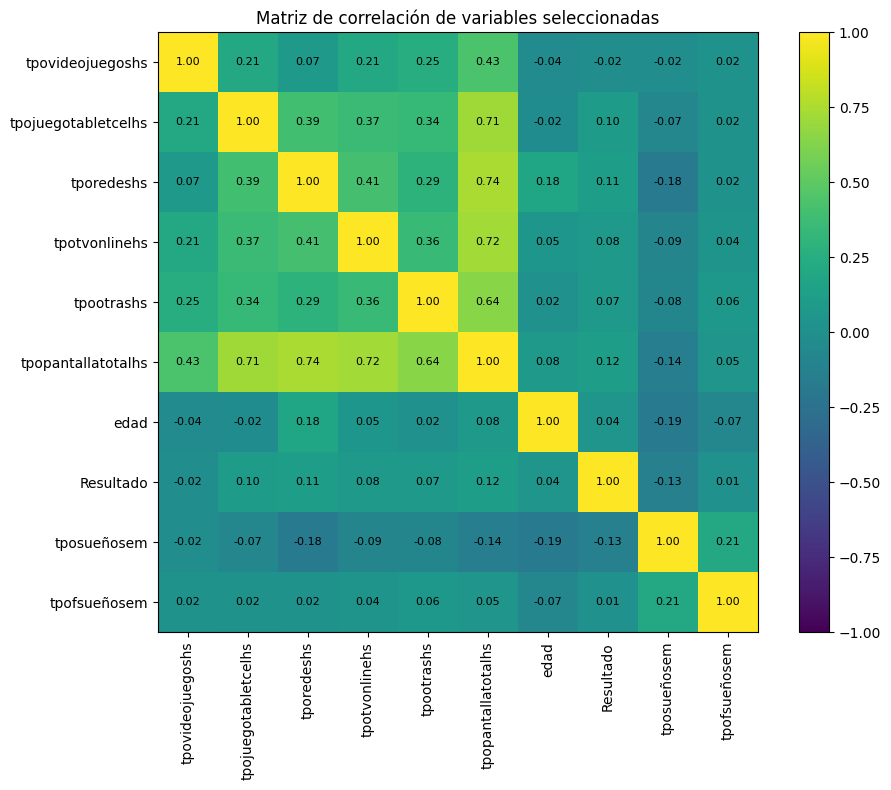

In [37]:
# Heatmap con matplotlib, limitado a un subconjunto para mantener legibilidad
corr_plot_cols = [
    c for c in [
        "tpovideojuegoshs",
        "tpojuegotabletcelhs",
        "tporedeshs",
        "tpotvonlinehs",
        "tpootrashs",
        "tpopantallatotalhs",
        "edad",
        "Resultado",
        "tposueñosem",
        "tpofsueñosem",
    ] if c in df.columns
]

if len(corr_plot_cols) >= 2:
    matriz = df[corr_plot_cols].corr()

    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(matriz, vmin=-1, vmax=1)

    ax.set_xticks(range(len(matriz.columns)))
    ax.set_xticklabels(matriz.columns, rotation=90)
    ax.set_yticks(range(len(matriz.columns)))
    ax.set_yticklabels(matriz.columns)

    for i in range(len(matriz.columns)):
        for j in range(len(matriz.columns)):
            ax.text(j, i, f"{matriz.iloc[i, j]:.2f}",
                    ha="center", va="center", fontsize=8)

    ax.set_title("Matriz de correlación de variables seleccionadas")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

**Interpretación y conclusión:**

Se conserva una sola representación de cada característica, utilizando las variables originales con validación propia. Las correlaciones entre originales y `trimmed` se calculan sobre pares disponibles: un valor de 1 no demuestra equivalencia de cobertura ni justifica preferir una versión que haya convertido observaciones en faltantes.

En las cinco actividades seleccionadas, las correlaciones de la población conservada son positivas, bajas a moderadas (aproximadamente 0,062 a 0,407). No se observan pares con redundancia lineal casi perfecta entre ellas. Esto apoya conservar cada actividad como dimensión, aunque no prueba independencia estadística. El total es la suma exacta de sus componentes en el archivo y se excluye de la entrada para evitar volver a ponderar información ya representada.


# 10 Agrupación conceptual de variables para limpieza y análisis

Para evitar mezclar funciones, se organizan las variables en grupos conceptuales.

In [38]:
variables_identificacion = [
    c for c in [
        "Submission ID", "Código"
    ] if c in df.columns
]

variables_intensidad = [
    c for c in [
        "tpovideojuegoshs",
        "tpojuegotabletcelhs",
        "tporedeshs",
        "tpotvonlinehs",
        "tpootrashs",
    ] if c in df.columns
]

variables_dispositivos = [
    c for c in [
        "PC o Laptop",
        "Teléfono celular 2",
        "Tablet",
        "Consola de juegos",
        "TV o Smart TV",
    ] if c in df.columns
]

variables_contexto = [
    c for c in [
        "WATCHTVbedtime7D01",
        "COMPUbedtime1D01",
        "COMPUbedtime2D01",
    ] if c in df.columns
]

variables_caracterizacion_demografica = [
    c for c in ["edad", "Sexo", "sexonum", "grado", "Colegio", "Ciudad"]
    if c in df.columns
]

variables_caracterizacion_sueno = [
    c for c in [
        "tposueñosem",
        "tpofsueñosem",
        "dursiestasemanahs",
        "difonsetsueño",
        "¿Cuánto tiempo en Minutos tardas en dormirte?",
    ] if c in df.columns
]

variables_caracterizacion_somnolencia = [
    c for c in ["Resultado", "somno01pdss"]
    if c in df.columns
]

variables_caracterizacion_academica = [
    c for c in ["lengua", "matematica", "prom", "aplazos"]
    if c in df.columns
]

grupos_variables = {
    "identificacion": variables_identificacion,
    "cluster_intensidad": variables_intensidad,
    "caracterizacion_dispositivos": variables_dispositivos,
    "caracterizacion_contexto": variables_contexto,
    "caracterizacion_demografica": variables_caracterizacion_demografica,
    "caracterizacion_sueno": variables_caracterizacion_sueno,
    "caracterizacion_somnolencia": variables_caracterizacion_somnolencia,
    "caracterizacion_academica": variables_caracterizacion_academica,
}

for nombre, lista in grupos_variables.items():
    print(f"\n{nombre}: {len(lista)} variables")
    for c in lista:
        print(" -", c)


identificacion: 2 variables
 - Submission ID
 - Código

cluster_intensidad: 5 variables
 - tpovideojuegoshs
 - tpojuegotabletcelhs
 - tporedeshs
 - tpotvonlinehs
 - tpootrashs

caracterizacion_dispositivos: 5 variables
 - PC o Laptop
 - Teléfono celular 2
 - Tablet
 - Consola de juegos
 - TV o Smart TV

caracterizacion_contexto: 3 variables
 - WATCHTVbedtime7D01
 - COMPUbedtime1D01
 - COMPUbedtime2D01

caracterizacion_demografica: 6 variables
 - edad
 - Sexo
 - sexonum
 - grado
 - Colegio
 - Ciudad

caracterizacion_sueno: 5 variables
 - tposueñosem
 - tpofsueñosem
 - dursiestasemanahs
 - difonsetsueño
 - ¿Cuánto tiempo en Minutos tardas en dormirte?

caracterizacion_somnolencia: 2 variables
 - Resultado
 - somno01pdss

caracterizacion_academica: 4 variables
 - lengua
 - matematica
 - prom
 - aplazos


### Selección de variables para limpieza y preprocesamiento

La intensidad se representa mediante las cinco variables originales de horas por actividad. Las frecuencias originales de dispositivos y los indicadores de contexto se conservan para caracterizar los perfiles, sin intervenir en el agrupamiento principal. Los identificadores solo permiten trazabilidad; demografía, sueño, somnolencia y notas se reservan para caracterizar los grupos.

La base de análisis incluye variables auxiliares; la sección 12 construye por separado la matriz de las cinco actividades, resuelve su completitud y aplica el escalado. No se excluyen participantes por carecer de notas o sueño cuando esas variables no forman parte de la entrada.


### Diccionario operativo y justificación de la selección

| Variable o familia | Unidad / significado | Función | Decisión |
|---|---|---|---|
| `tpovideojuegoshs` | Horas diarias de videojuegos | Entrada | Conservar original validada de 0 a 24 |
| `tpojuegotabletcelhs` | Horas diarias de juegos en móvil/tablet | Entrada | Conservar original validada de 0 a 24 |
| `tporedeshs` | Horas diarias en redes sociales | Entrada | Conservar original validada de 0 a 24 |
| `tpotvonlinehs` | Horas diarias de TV/streaming | Entrada | Conservar original validada de 0 a 24 |
| `tpootrashs` | Horas diarias de otras actividades con pantallas | Entrada | Conservar original validada de 0 a 24 |
| Frecuencias originales de dispositivos | Días de uso en la hora previa a dormir | Caracterización | Enteros de 0 a 7; no incorporarlas al ajuste principal |
| Indicadores de contexto | Categorías concretas verificadas en 7.6 | Caracterización | No interpretar 0 como ausencia de uso; revisar frecuencia de origen |
| Edad, sexo y grado | Características demográficas | Caracterización | Edad conocida 12 a 18; desconocida conservada con sensibilidad específica |
| Duración de sueño | Horas de sueño declaradas/derivadas | Caracterización | Originales entre 0 y 24; cero señalado para revisión |
| `Resultado` | Puntaje PDSS de 0 a 32 | Caracterización | Utilizar el puntaje sin asignarle valor diagnóstico |
| Lengua, matemática y promedio | Notas de 0 a 10 | Caracterización | Mantener faltantes y mostrar denominadores |
| Identificadores y `fila_origen` | Trazabilidad | Vinculación | Nunca ingresar como predictores |

La prioridad es describir la intensidad absoluta y su distribución entre actividades. No se normaliza cada fila a porcentajes, porque eso eliminaría la diferencia entre dos participantes con igual composición pero distinta intensidad. La estandarización por columna cambia el peso relativo de cada actividad y se explicita en 12.1. Las cinco dimensiones tienen peso comparable en la escala estandarizada; no se incorporan ponderaciones clínicas o educativas sin fundamento externo.


# 11 Limpieza y preprocesamiento

In [39]:
# Base de análisis: originales seleccionadas y variables auxiliares.
columnas_requeridas = (
    list(pares_consumo) + vars_dispositivos_raw
    + ["tposueñosem", "tpofsueñosem"]
)
faltan_originales = sorted(set(columnas_requeridas) - set(df.columns))
if faltan_originales:
    raise ValueError(f"Faltan variables originales esperadas: {faltan_originales}")

columnas_seleccionadas = list(dict.fromkeys(
    variables_identificacion + variables_intensidad + variables_dispositivos
    + variables_contexto + variables_caracterizacion_demografica
    + variables_caracterizacion_sueno + variables_caracterizacion_somnolencia
    + variables_caracterizacion_academica
))
df_limpio = df[columnas_seleccionadas].copy()


In [40]:
print("Cant. Variables df_limpio",df_limpio.shape[1])

Cant. Variables df_limpio 32


In [41]:
df_limpio.columns

Index(['Submission ID', 'Código', 'tpovideojuegoshs', 'tpojuegotabletcelhs',
       'tporedeshs', 'tpotvonlinehs', 'tpootrashs', 'PC o Laptop',
       'Teléfono celular 2', 'Tablet', 'Consola de juegos', 'TV o Smart TV',
       'WATCHTVbedtime7D01', 'COMPUbedtime1D01', 'COMPUbedtime2D01', 'edad',
       'Sexo', 'sexonum', 'grado', 'Colegio', 'Ciudad', 'tposueñosem',
       'tpofsueñosem', 'dursiestasemanahs', 'difonsetsueño',
       '¿Cuánto tiempo en Minutos tardas en dormirte?', 'Resultado',
       'somno01pdss', 'lengua', 'matematica', 'prom', 'aplazos'],
      dtype='object')

In [42]:
# Filtramos los registros con edad informada al rango de 12 a 18 años.
# Los registros sin edad informada se conservan para no descartar casos
# que puedan contener información válida para la segmentación.

if "edad" in df_limpio.columns:
    fuera_rango = df_limpio["edad"].notna() & ~df_limpio["edad"].between(12, 18, inclusive="both")
    n_fuera = int(fuera_rango.sum())

    df_limpio = df_limpio.loc[~fuera_rango].copy()
else:
  print('NO')
print("Dimensiones luego de aplicar rango etario documentado:", df_limpio.shape)

Dimensiones luego de aplicar rango etario documentado: (4062, 32)


In [43]:
# Validación del filtro etario aplicado:
# verificamos la cantidad de registros resultantes, los valores faltantes
# y que las edades informadas se encuentren dentro del rango de 12 a 18 años.
print("Registros finales:", len(df_limpio))
print("Edad faltante:", df_limpio["edad"].isna().sum())
print("Edad mínima:", df_limpio["edad"].min())
print("Edad máxima:", df_limpio["edad"].max())

Registros finales: 4062
Edad faltante: 562
Edad mínima: 12.0
Edad máxima: 18.0


In [44]:
# Validación propia sobre las variables originales, sin modificar df_original.
# Se ejecuta después del filtro etario y antes de describir/exportar la base.
reglas_dominio = {
    **{c: (0, 24, False) for c in variables_intensidad},
    **{c: (0, 7, True) for c in variables_dispositivos},
    **{c: (0, 24, False) for c in ["tposueñosem", "tpofsueñosem"]},
}
resumen_validacion = []
detalles_validacion = []
for columna, (minimo, maximo, entero) in reglas_dominio.items():
    entrada = df_limpio[columna].copy()
    valores = pd.to_numeric(entrada, errors="coerce")
    no_numerico = entrada.notna() & valores.isna()
    no_finito = valores.notna() & ~np.isfinite(valores)
    fuera_rango = valores.notna() & np.isfinite(valores) & ~valores.between(minimo, maximo)
    no_entero = pd.Series(False, index=valores.index)
    if entero:
        no_entero = valores.notna() & np.isfinite(valores) & (valores % 1 != 0)
    invalidos = no_numerico | no_finito | fuera_rango | no_entero
    motivo = pd.Series("", index=valores.index, dtype=object)
    motivo.loc[no_numerico] = "no numérico"
    motivo.loc[no_finito] = "no finito"
    motivo.loc[fuera_rango] = "fuera de rango"
    motivo.loc[no_entero & ~fuera_rango] = "días no enteros"
    if invalidos.any():
        detalles_validacion.append(pd.DataFrame({
            "fila_origen": entrada.index[invalidos],
            "variable": columna,
            "valor_original": entrada.loc[invalidos].to_numpy(),
            "motivo": motivo.loc[invalidos].to_numpy(),
        }))
    df_limpio[columna] = valores.mask(invalidos)
    resumen_validacion.append({
        "variable": columna, "rango": f"{minimo} a {maximo}",
        "requiere_entero": entero,
        "faltantes_previos": int(entrada.isna().sum()),
        "valores_invalidados": int(invalidos.sum()),
        "faltantes_resultantes": int(df_limpio[columna].isna().sum()),
    })
resumen_validacion = pd.DataFrame(resumen_validacion)
registro_validacion = (
    pd.concat(detalles_validacion, ignore_index=True) if detalles_validacion
    else pd.DataFrame(columns=["fila_origen", "variable", "valor_original", "motivo"])
)
display(resumen_validacion)
display(registro_validacion.head(30))
print("Consumos >12 h conservados por actividad (requieren revisión):")
display(df_limpio[variables_intensidad].gt(12).sum().rename("cantidad").to_frame())
print("Duraciones de sueño iguales a cero (requieren revisión):")
display(df_limpio[["tposueñosem", "tpofsueñosem"]].eq(0).sum().to_frame("cantidad"))


,variable,rango,requiere_entero,faltantes_previos,valores_invalidados,faltantes_resultantes
0,tpovideojuegoshs,0 a 24,False,0,0,0
1,tpojuegotabletcelhs,0 a 24,False,0,0,0
2,tporedeshs,0 a 24,False,0,0,0
3,tpotvonlinehs,0 a 24,False,0,0,0
4,tpootrashs,0 a 24,False,0,0,0
5,PC o Laptop,0 a 7,True,0,17,17
6,Teléfono celular 2,0 a 7,True,0,204,204
7,Tablet,0 a 7,True,0,9,9
8,Consola de juegos,0 a 7,True,0,25,25
9,TV o Smart TV,0 a 7,True,0,57,57


,fila_origen,variable,valor_original,motivo
0,36,PC o Laptop,9.0,fuera de rango
1,200,PC o Laptop,9.0,fuera de rango
2,227,PC o Laptop,9.0,fuera de rango
3,349,PC o Laptop,9.0,fuera de rango
4,377,PC o Laptop,9.0,fuera de rango
5,490,PC o Laptop,8.0,fuera de rango
6,794,PC o Laptop,9.0,fuera de rango
7,1274,PC o Laptop,9.0,fuera de rango
8,1490,PC o Laptop,8.0,fuera de rango
9,2244,PC o Laptop,9.0,fuera de rango


Consumos >12 h conservados por actividad (requieren revisión):


,cantidad
tpovideojuegoshs,30
tpojuegotabletcelhs,113
tporedeshs,247
tpotvonlinehs,112
tpootrashs,67


Duraciones de sueño iguales a cero (requieren revisión):


,cantidad
tposueñosem,0
tpofsueñosem,16


## Representaciones excluidas y justificación

- **Versiones `trimmed` de horas por actividad:** se utilizan las originales para conservar usos intensivos, con validación propia de 0 a 24 horas diarias. El umbral de 12 horas del estudio no se adopta como filtro de este clustering.
- **Versiones `trimmed` y binarias de frecuencia de dispositivos:** se conservan las frecuencias originales para caracterización, con validación de días enteros de 0 a 7. La auditoría de 7.5 verifica la equivalencia observada de esta validación con las versiones `trimmed`.
- **Duraciones de sueño `TRIMMED`:** se conservan las originales para caracterización, con validación explícita de duración. No ingresan al clustering.
- **Porcentajes y tiempo total de pantalla:** se excluyen de la entrada para no duplicar la representación de los componentes. Los porcentajes también introducen una dependencia composicional.
- **Identificadores, columnas administrativas y otras variables no seleccionadas:** no representan dimensiones del perfil digital. Los identificadores seleccionados se conservan solo para trazabilidad.
- **WAZ:** no se incorpora por su elevada ausencia de información y falta de pertinencia para este objetivo.

Las versiones alternativas permanecen disponibles en `df_original` y en el EDA comparativo; no se incorporan a `df_limpio`.


# 12 Descripción del dataset luego de la limpieza

In [45]:
n_original = len(df_original)
n_limpio = len(df_limpio)
n_vars_original = df_original.shape[1]
n_vars_limpio = df_limpio.shape[1]

display(Markdown(f'''
### Dataset resultante

- Registros originales: **{n_original:,}**
- Registros luego del filtro poblacional: **{n_limpio:,}**
- Variables originales: **{n_vars_original}**
- Variables conservadas en `df_limpio`: **{n_vars_limpio}**

Las variables demográficas, de sueño, somnolencia y rendimiento académico se conservan en df_limpio para la caracterización posterior de los clusters, pero no se utilizarán como variables de entrada para la formación de los grupos. De esta manera, los clusters se construirán a partir de los patrones de consumo digital y posteriormente podrán analizarse sus diferencias respecto de estas características externas.
'''))


### Dataset resultante

- Registros originales: **4,115**
- Registros luego del filtro poblacional: **4,062**
- Variables originales: **125**
- Variables conservadas en `df_limpio`: **32**

Las variables demográficas, de sueño, somnolencia y rendimiento académico se conservan en df_limpio para la caracterización posterior de los clusters, pero no se utilizarán como variables de entrada para la formación de los grupos. De esta manera, los clusters se construirán a partir de los patrones de consumo digital y posteriormente podrán analizarse sus diferencias respecto de estas características externas.


In [46]:
# Resumen de la estructura del dataset resultante
resumen_limpio = pd.DataFrame({
    "Tipo de dato": df_limpio.dtypes.astype(str),
    "Nulos": df_limpio.isna().sum(),
    "% Nulos": (df_limpio.isna().mean() * 100).round(2)
})

display(resumen_limpio)

,Tipo de dato,Nulos,% Nulos
Submission ID,int64,0,0.00
Código,object,0,0.00
tpovideojuegoshs,float64,0,0.00
tpojuegotabletcelhs,float64,0,0.00
tporedeshs,float64,0,0.00
tpotvonlinehs,float64,0,0.00
tpootrashs,float64,0,0.00
PC o Laptop,float64,17,0.42
Teléfono celular 2,float64,204,5.02
Tablet,float64,9,0.22


**Conclusión:**

`df_limpio` conserva la base de análisis y las variables auxiliares. La matriz principal se construye exclusivamente con las cinco variables originales de horas por actividad. Las frecuencias de dispositivos, contexto de uso, demografía, sueño, somnolencia y notas se reservan para caracterización.

Se utiliza una política explícita de casos completos en las cinco entradas, sin imputación. En el archivo actual las cinco variables permanecen completas tras la validación de dominio, por lo que esta política no descarta registros adicionales. Los faltantes auxiliares se conservan y cada descripción posterior deberá informar su cantidad de observaciones válidas. La edad desconocida sigue admitida según el criterio poblacional previo: no puede asegurarse que esos participantes pertenezcan al rango de 12 a 18 años, y esta limitación deberá reconocerse al interpretar los perfiles.


## 12.1 Matriz de referencia de cinco entradas

Se utilizan exclusivamente estas cinco variables originales, medidas en horas diarias: `tpovideojuegoshs`, `tpojuegotabletcelhs`, `tporedeshs`, `tpotvonlinehs` y `tpootrashs`. Así los grupos describen intensidad y distribución del consumo entre actividades. Las frecuencias de uso cerca de dormir y los indicadores de contexto se reservan para caracterización, evitando introducir otra dimensión en la definición del perfil principal. Esta selección es una decisión del presente trabajo.

**Faltantes:** se aplica selección de casos completos únicamente en esas cinco entradas, después de las validaciones. No se imputan valores ni se interpreta un faltante como cero. En este archivo la auditoría muestra que no faltan valores en esas entradas, por lo que no se pierden participantes adicionales. Si se actualiza el dataset, la tabla siguiente mostrará cuántos se excluyen y deberá revisarse el posible sesgo de selección. Los faltantes de notas, sueño, dispositivos u otras variables auxiliares no se usan como filtro.

**Escalado:** se utiliza `StandardScaler` para que las distancias no queden dominadas exclusivamente por las actividades de mayor dispersión. Aunque todas se expresen en horas, sus varianzas difieren. Esta elección otorga una escala comparable por actividad y modifica su peso respecto de usar horas sin escalar; no elimina la asimetría ni la influencia de extremos. Se conservan también los valores en horas para interpretar los futuros centroides. El escalador se ajusta sobre la muestra exploratoria actual; ante nuevas observaciones se reutilizarán estos mismos parámetros, sin reajustarlos.

`X_cluster` contiene únicamente las entradas en horas; `X_cluster_scaled` es la matriz numérica que ingresará al algoritmo. `df_caracterizacion` conserva las mismas filas y las variables auxiliares. El índice de origen permite vincular las tres tablas y no se utiliza como predictor. Los controles de la matriz final se presentan en la sección 12.2.


In [47]:
# Lista explícita: no seleccionar columnas por tipo numérico o por posición.
variables_cluster = [
    "tpovideojuegoshs", "tpojuegotabletcelhs", "tporedeshs",
    "tpotvonlinehs", "tpootrashs",
]
entradas = df_limpio[variables_cluster].copy()
resumen_faltantes_cluster = pd.DataFrame({
    "faltantes": entradas.isna().sum(),
    "porcentaje_faltantes": entradas.isna().mean() * 100,
})
display(resumen_faltantes_cluster)
casos_completos_cluster = entradas.notna().all(axis=1)
X_cluster = entradas.loc[casos_completos_cluster].copy()
df_caracterizacion = df_limpio.loc[casos_completos_cluster].copy()
if len(X_cluster) < 2:
    raise ValueError("No hay suficientes casos completos para clustering.")
if not np.isfinite(X_cluster.to_numpy(dtype=float)).all():
    raise ValueError("Hay valores no finitos en la matriz de entrada.")
if not X_cluster.ge(0).all().all() or not X_cluster.le(24).all().all():
    raise ValueError("Hay tiempos por actividad fuera del dominio validado.")
if X_cluster.nunique().le(1).any():
    raise ValueError("Hay actividades constantes; revisar antes del escalado.")
scaler_cluster = StandardScaler()
X_cluster_scaled = pd.DataFrame(
    scaler_cluster.fit_transform(X_cluster),
    columns=variables_cluster, index=X_cluster.index,
)
assert X_cluster_scaled.index.equals(df_caracterizacion.index)
assert np.isfinite(X_cluster_scaled.to_numpy()).all()
assert np.allclose(X_cluster_scaled.mean(), 0, atol=1e-8)
assert np.allclose(X_cluster_scaled.std(ddof=0), 1, atol=1e-8)
resumen_matriz_cluster = pd.DataFrame([{
    "registros_base": len(df_limpio),
    "excluidos_por_faltantes_entradas": int((~casos_completos_cluster).sum()),
    "registros_matriz": len(X_cluster),
    "variables_entrada": len(variables_cluster),
    "faltantes_matriz": int(X_cluster.isna().sum().sum()),
}])
display(resumen_matriz_cluster)
display(X_cluster_scaled.describe())


,faltantes,porcentaje_faltantes
tpovideojuegoshs,0,0.0
tpojuegotabletcelhs,0,0.0
tporedeshs,0,0.0
tpotvonlinehs,0,0.0
tpootrashs,0,0.0


,registros_base,excluidos_por_faltantes_entradas,registros_matriz,variables_entrada,faltantes_matriz
0,4062,0,4062,5,0


,tpovideojuegoshs,tpojuegotabletcelhs,tporedeshs,tpotvonlinehs,tpootrashs
count,4.062000e+03,4.062000e+03,4.062000e+03,4.062000e+03,4.062000e+03
mean,-3.148638e-17,5.772504e-17,2.798790e-17,5.685042e-17,5.772504e-17
std,1.000123e+00,1.000123e+00,1.000123e+00,1.000123e+00,1.000123e+00
min,-4.629896e-01,-6.375726e-01,-8.696448e-01,-8.375082e-01,-3.943660e-01
25%,-4.629896e-01,-5.913374e-01,-6.570529e-01,-5.561725e-01,-3.943660e-01
50%,-4.629896e-01,-3.601612e-01,-3.027332e-01,-2.748368e-01,-3.943660e-01
75%,8.862584e-02,1.946615e-01,1.933145e-01,1.471668e-01,-6.292392e-02
max,9.397135e+00,5.974065e+00,4.197128e+00,5.867660e+00,7.505004e+00


In [48]:
# Trazabilidad de la población y preparación final.
flujo_muestra = pd.DataFrame([
    {"etapa":"Archivo original","registros":len(df_original),"variables":df_original.shape[1]},
    {"etapa":"Base seleccionada y filtro etario","registros":len(df_limpio),"variables":df_limpio.shape[1]},
    {"etapa":"Casos completos en las cinco entradas","registros":len(X_cluster),"variables":X_cluster.shape[1]},
    {"etapa":"Matriz estandarizada","registros":len(X_cluster_scaled),"variables":X_cluster_scaled.shape[1]},
])
display(flujo_muestra)
print("Excluidos por edad informada fuera de 12 a 18:", len(df_original)-len(df_limpio))
print("Edad desconocida entre los casos del modelo:", int(df_caracterizacion["edad"].isna().sum()))
print("Filas excluidas por faltantes en las entradas:", int((~casos_completos_cluster).sum()))


,etapa,registros,variables
0,Archivo original,4115,125
1,Base seleccionada y filtro etario,4062,32
2,Casos completos en las cinco entradas,4062,5
3,Matriz estandarizada,4062,5


Excluidos por edad informada fuera de 12 a 18: 53
Edad desconocida entre los casos del modelo: 562
Filas excluidas por faltantes en las entradas: 0


## 12.2 Preparación y control de la matriz final

Se conservan las cinco actividades en horas originales validadas y se estandarizan antes de K-Means. Los seis participantes con consumo cero permanecen en la matriz: cero es una respuesta válida y no un dato faltante. Las banderas de valores altos se informan como diagnóstico, sin excluir casos por su intensidad.

In [49]:
R = Path("resultados_proyecto_k3")
R.mkdir(exist_ok=True)
V = list(variables_intensidad)
ETIQUETAS = ["Videojuegos", "Juegos móvil/tablet", "Redes", "TV/streaming", "Otras"]
assert len(V) == 5

# Banderas sobre la población validada; no se utilizan como filtros.
banderas_extremos = pd.DataFrame({"suma_actividades": X_cluster.sum(axis=1),
    "n_actividades_mayor12": X_cluster.gt(12).sum(axis=1),
    "alguna_mayor_igual23": X_cluster.ge(23).any(axis=1)})
print("Alguna actividad >12 h:", int(banderas_extremos.n_actividades_mayor12.gt(0).sum()))
print("Suma >24 h (bandera, no filtro):", int(banderas_extremos.suma_actividades.gt(24).sum()))

X_horas = X_cluster.copy()
print("Matriz final de horas:", X_horas.shape)


Alguna actividad >12 h: 367
Suma >24 h (bandera, no filtro): 390
Matriz final de horas: (4062, 5)


# 13 Exportación del dataset limpio
Los archivos se generan junto a la notebook al ejecutar todas las celdas:

- `dataset_limpio_originales.xlsx` / `.csv`: base de análisis y caracterización.
- `dataset_clustering_horas.csv`: cinco entradas en horas, con clave de fila.
- `dataset_clustering_escalado.csv`: cinco entradas estandarizadas, con clave de fila.
- `dataset_caracterizacion.csv`: variables auxiliares alineadas con las entradas.
- `parametros_escalado.csv` y registros de validación: trazabilidad del procesamiento.

Al leer los CSV para entrenar, `fila_origen` se utiliza como índice y no como característica. En Colab se ofrece la descarga de la base de análisis; los demás archivos quedan accesibles en su panel de archivos. No se ha publicado un enlace externo al dataset derivado.


In [50]:
# Exportación de la base con validación propia (no es la matriz final escalada).
df_limpio.to_csv("dataset_limpio_originales.csv", index=False)
df_limpio.to_excel("dataset_limpio_originales.xlsx", index=False)
resumen_validacion.to_csv("resumen_validacion_originales.csv", index=False)
registro_validacion.to_csv("registro_validacion_originales.csv", index=False)
print("Base de análisis exportada:", df_limpio.shape)
X_cluster.to_csv("dataset_clustering_horas.csv", index=True, index_label="fila_origen")
X_cluster_scaled.to_csv("dataset_clustering_escalado.csv", index=True, index_label="fila_origen")
df_caracterizacion.to_csv("dataset_caracterizacion.csv", index=True, index_label="fila_origen")
parametros_escalado = pd.DataFrame({
    "variable": variables_cluster,
    "media": scaler_cluster.mean_, "escala": scaler_cluster.scale_,
})
parametros_escalado.to_csv("parametros_escalado.csv", index=False)
print("Matriz de K-Means exportada:", X_cluster_scaled.shape)
print("fila_origen es una clave de vinculación; no ingresarla al algoritmo.")


Base de análisis exportada: (4062, 32)
Matriz de K-Means exportada: (4062, 5)
fila_origen es una clave de vinculación; no ingresarla al algoritmo.


In [51]:
# Descarga de la base de análisis en Colab
if files is not None:
    files.download("dataset_limpio_originales.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 14. Modelo de Aprendizaje Automático propuesto

El problema es de **aprendizaje automático no supervisado** porque no existe una etiqueta objetivo conocida que indique de antemano a qué perfil pertenece cada adolescente.

El objetivo es explorar si existen agrupamientos naturales a partir de similitudes en los patrones de consumo digital. La posibilidad de obtener una partición con K-Means no demuestra por sí misma que esos grupos estén naturalmente separados; esa hipótesis se contrasta mediante las evaluaciones posteriores.

## Modelo inicial: K-Means

K-Means se propone como modelo de referencia (baseline) porque:

- es un algoritmo clásico de segmentación;
- presenta un costo computacional adecuado para un dataset de este tamaño;
- permite trabajar con variables numéricas estandarizadas;
- produce grupos cuyos patrones medios pueden interpretarse y compararse;
- permite comparar diferentes valores de `K`;
- facilita la posterior caracterización de cada grupo.

### Limitaciones

K-Means favorece grupos relativamente compactos en términos de distancia euclidiana y es sensible a:

- la escala de las variables;
- los valores extremos;
- la elección de `K`;
- la presencia de estructuras no esféricas.

También genera una partición aunque no existan grupos claramente separados. Por eso se evalúan tanto la calidad de esa partición como las limitaciones derivadas de la escala y los valores extremos.

### Alternativas investigadas por el equipo

- **Clustering jerárquico:** útil para estudiar relaciones jerárquicas entre observaciones o grupos. Se considera como alternativa conceptual, sin entrenamiento en esta notebook.
- **DBSCAN:** útil cuando existen grupos de formas irregulares y ruido, aunque puede ser sensible a sus hiperparámetros y a la escala. Se considera como alternativa conceptual, sin entrenamiento en esta notebook.
- **Gaussian Mixture Models:** permite una asignación probabilística y mayor flexibilidad en la geometría de los grupos. Se mantiene como alternativa conceptual, sin entrenamiento en la versión actual.

En función de estas características, **K-Means es el modelo seleccionado como referencia del trabajo**. Se comparan diferentes valores de `K` y se conserva **K=3 como segmentación descriptiva**, explicitando las limitaciones que surgen de su evaluación, sin presentarlo como una cantidad de grupos naturales demostrada.

Las cinco variables de horas originales se estandarizan antes del ajuste. Se explora la cantidad de grupos mediante codo y silhouette; luego se desarrolla K=3 y se caracteriza cada perfil. Como complemento se estudia si incorporar edad y sexo modifica la segmentación para K=3, sin sustituir el modelo principal.

### Alcance de la evaluación

El modelo tiene finalidad exploratoria: no predice una etiqueta conocida. Por ello se ajusta sobre la muestra disponible y se utilizan indicadores internos, sin informar exactitud de clasificación ni una prueba de desempeño predictivo. En esta etapa no se evalúa estabilidad mediante remuestreo ni validación en una cohorte independiente. La reproducibilidad de la ejecución no equivale a demostrar estabilidad poblacional.

Las cinco entradas describen horas declaradas por actividad. Las variables demográficas, de sueño y académicas se reservan inicialmente para caracterización. Solo en el experimento complementario del punto 19 se incorporan edad y sexo como entradas, lo que cambia explícitamente la pregunta del análisis.


# 15. Exploración de la cantidad de grupos

Antes de desarrollar K=3 se exploran K=1 a K=10 sobre las cinco horas originales estandarizadas. Se combinan el método del codo, silhouette y tamaños para valorar si hay evidencia de una partición adecuada. La búsqueda es exploratoria: no se presupone que existan grupos naturales.
**Cómo leer los indicadores:** la inercia es la suma de distancias cuadradas a los centroides y disminuye al aumentar K; se busca una reducción del beneficio adicional, no su mínimo absoluto. Silhouette compara la cohesión dentro del grupo con la proximidad al grupo alternativo y toma valores entre −1 y 1: valores altos indican mejor separación, cercanos a cero indican fronteras débiles y negativos sugieren mayor proximidad media a otro grupo. No está definido para K=1, por lo que esa fila solo aporta inercia. Todas las soluciones se comparan sobre las mismas personas y la misma matriz estandarizada.


,k,n,inercia,silhouette,grupo_menor_n
0,1,4062,20310.000,NaN,4062
1,2,4062,14924.837,0.638,397
2,3,4062,12851.464,0.556,86
3,4,4062,11188.881,0.447,70
4,5,4062,10016.008,0.449,66
5,6,4062,9090.045,0.442,64
6,7,4062,8181.639,0.403,25
7,8,4062,7494.780,0.348,24
8,9,4062,6927.690,0.344,25
9,10,4062,6477.814,0.293,25


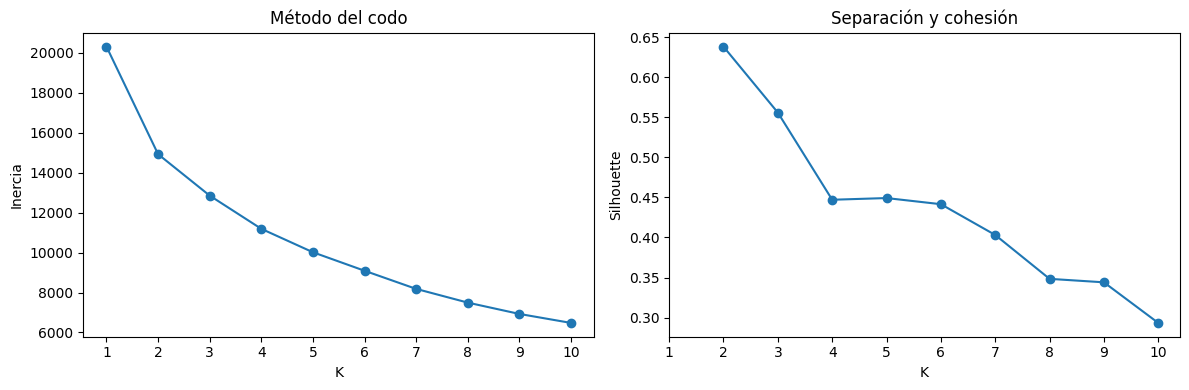

**Lectura:** el mayor silhouette entre K=2 y K=10 corresponde a **K=2**. La inercia disminuye al aumentar K por construcción; el codo se interpreta visualmente y puede ser ambiguo. Ninguno de estos diagnósticos demuestra una cantidad natural de grupos ni descarta una estructura continua. Se conserva K=3 por su utilidad descriptiva, diferenciando esta decisión del máximo de silhouette. Los tamaños y los resultados por grupo deben considerarse junto al promedio global.

In [52]:
# Se explora K antes de fijar una solución descriptiva.
z_exploracion = StandardScaler().fit_transform(X_horas)
filas_k = []
modelos_exploracion = {}
with threadpool_limits(limits=2):
    for k in range(1, 11):
        m = KMeans(n_clusters=k, n_init=20, random_state=42, max_iter=500).fit(z_exploracion)
        modelos_exploracion[k] = m
        filas_k.append({"k": k, "n": len(X_horas), "inercia": m.inertia_,
            "silhouette": silhouette_score(z_exploracion, m.labels_) if k > 1 else np.nan,
            "grupo_menor_n": int(pd.Series(m.labels_).value_counts().min())})
comparacion_k = pd.DataFrame(filas_k)
display(comparacion_k.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(comparacion_k.k, comparacion_k.inercia, 'o-')
axes[0].set(title='Método del codo', xlabel='K', ylabel='Inercia', xticks=range(1, 11))
axes[1].plot(comparacion_k.k, comparacion_k.silhouette, 'o-')
axes[1].set(title='Separación y cohesión', xlabel='K', ylabel='Silhouette', xticks=range(1, 11))
plt.tight_layout()
plt.savefig(R/'seleccion_k.png', dpi=160)
plt.show()
mejor_k_sil = int(comparacion_k.loc[comparacion_k.silhouette.idxmax(), 'k'])
display(Markdown(f"**Lectura:** el mayor silhouette entre K=2 y K=10 corresponde a **K={mejor_k_sil}**. "
    "La inercia disminuye al aumentar K por construcción; el codo se interpreta visualmente y puede ser ambiguo. "
    "Ninguno de estos diagnósticos demuestra una cantidad natural de grupos ni descarta una estructura continua. "
    "Se conserva K=3 por su utilidad descriptiva, diferenciando esta decisión del máximo de silhouette. "
    "Los tamaños y los resultados por grupo deben considerarse junto al promedio global."))


### Interpretación de la exploración y elección de K=3

En el rango evaluado, **K=2 presenta el mayor silhouette global (0,638)** y es, según ese indicador, la alternativa mejor puntuada. Sin embargo, esta solución ofrece una descripción más general de la heterogeneidad del consumo. La inercia disminuye al aumentar K, como ocurre por construcción, y el método del codo no identifica por sí solo una cantidad inequívoca de grupos naturales.

Con **K=3**, silhouette alcanza **0,556**. Al pasar a **K=4**, desciende a **0,447** y el grupo menor pasa de 86 a 70 participantes. Esto sugiere que aumentar la segmentación reduce la separación y cohesión promedio según este indicador y genera subdivisiones cuya utilidad requiere justificación. No permite afirmar, por sí solo, que K=4 distorsione los datos. K=5 tampoco recupera el nivel de K=3 (silhouette de 0,449).

Por estas razones, **se conserva K=3 como solución descriptiva principal**, retomando la propuesta del equipo: ofrece mayor detalle que K=2 y mantiene una mejor puntuación global que K=4 y K=5. Esta elección constituye un compromiso entre detalle, calidad interna e interpretabilidad; **no se presenta como el óptimo estadístico demostrado ni como evidencia de tres grupos naturales**. En el punto 16 se desarrolla y representa esta solución, revisando también los tamaños, la separación de cada grupo y sus limitaciones.

# 16. Entrenamiento y evaluación de K-Means con K=3

Se ajusta K-Means sobre las cinco variables originales de horas estandarizadas, con 4.062 participantes, 20 inicializaciones, máximo 500 iteraciones y semilla 42. Se conserva la solución principal definida en el proyecto. Los números de grupo se ordenan por la suma de medias de horas para facilitar su lectura.

Se informan silhouette global y por grupo, tamaños y porcentaje de asignaciones con silhouette negativo. El promedio global puede ocultar debilidades en grupos pequeños. PCA se utiliza exclusivamente para visualizar la matriz estandarizada en dos dimensiones: el clustering se entrena sobre las cinco entradas, no sobre la proyección.


In [53]:
def ajustar(datos, nombre, k=3):
    pre = StandardScaler()
    z = pre.fit_transform(datos)
    with threadpool_limits(limits=2):
        m = KMeans(n_clusters=k, n_init=20, random_state=42, max_iter=500).fit(z)
        sil = silhouette_samples(z, m.labels_)
    orden = datos.groupby(m.labels_).mean().sum(axis=1).sort_values().index.tolist()
    mapa = {int(e): i + 1 for i, e in enumerate(orden)}
    grupos = pd.Series([mapa[int(e)] for e in m.labels_], index=datos.index, name="grupo")
    sil = pd.Series(sil, index=datos.index, name="silhouette")
    resumen = grupos.value_counts().sort_index().to_frame("n")
    resumen["porcentaje"] = resumen.n / len(grupos) * 100
    resumen["silhouette_medio"] = sil.groupby(grupos).mean()
    resumen["negativo_pct"] = sil.lt(0).groupby(grupos).mean() * 100
    resumen["alguna_actividad_mayor12_pct"] = datos.gt(12).any(axis=1).groupby(grupos).mean() * 100
    pipeline = Pipeline([("representacion", pre), ("kmeans", m)])
    assert np.array_equal([mapa[int(e)] for e in pipeline.predict(datos)], grupos)
    return {"nombre": nombre, "datos": datos, "z": z, "modelo": m, "pre": pre, "mapa": mapa,
            "grupos": grupos, "silhouette": sil, "resumen": resumen, "pipeline": pipeline,
            "medias": datos.groupby(grupos).mean(), "medianas": datos.groupby(grupos).median()}


referencia = ajustar(X_horas, "original")
NOMBRES_REFERENCIA = {1: "Menor intensidad relativa", 2: "Uso elevado de redes y juegos móviles", 3: "Consumo múltiple extremo declarado"}
referencia["resumen"]["nombre_descriptivo"] = referencia["resumen"].index.map(NOMBRES_REFERENCIA)
print("K=3 sobre horas originales:")
display(referencia["resumen"].round(3))
display(referencia["medias"].round(2))
display(referencia["medianas"].round(2))


K=3 sobre horas originales:


,n,porcentaje,silhouette_medio,negativo_pct,alguna_actividad_mayor12_pct,nombre_descriptivo
grupo,,,,,,
1,3545,87.272,0.638,0.000,0.423,Menor intensidad relativa
2,431,10.611,-0.019,48.956,62.877,Uso elevado de redes y juegos móviles
3,86,2.117,0.046,38.372,94.186,Consumo múltiple extremo declarado


,tpovideojuegoshs,tpojuegotabletcelhs,tporedeshs,tpotvonlinehs,tpootrashs
grupo,,,,,
1,0.97,1.58,2.83,2.21,0.75
2,1.21,6.65,12.82,7.62,1.70
3,6.93,10.06,12.37,11.23,16.85


,tpovideojuegoshs,tpojuegotabletcelhs,tporedeshs,tpotvonlinehs,tpootrashs
grupo,,,,,
1,0.0,1.00,2.0,2.00,0.00
2,0.0,5.00,12.0,5.17,0.00
3,3.0,7.58,12.0,10.00,18.83


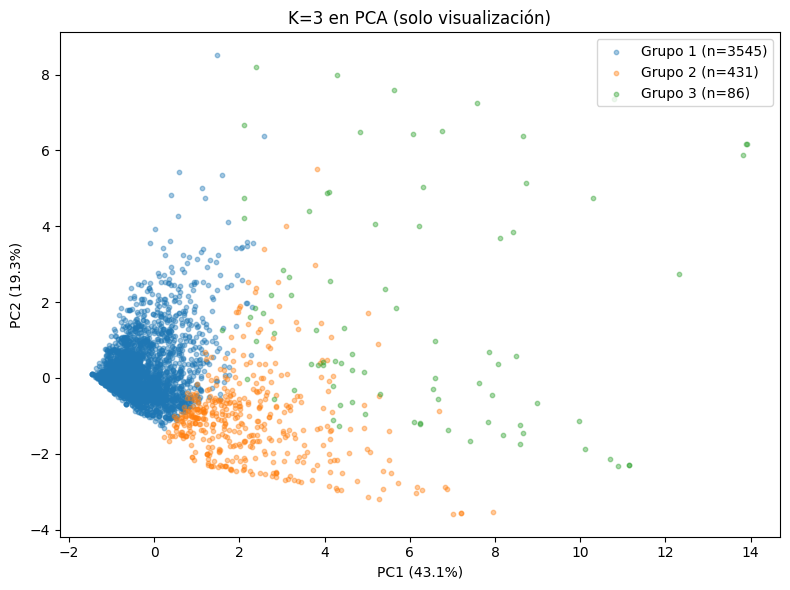

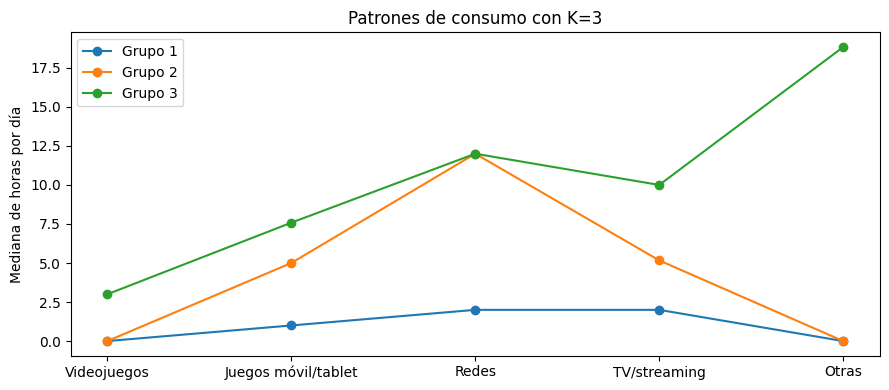

**Lectura de la visualización:** las dos componentes representan el 62.4% de la varianza de las cinco entradas estandarizadas. El plano permite observar un núcleo mayoritario y respuestas que se extienden hacia consumos elevados. El solapamiento y las distancias del plano no resumen toda la información de las cinco dimensiones; PCA no valida por sí sola los grupos. El gráfico de medianas permite interpretar las actividades que diferencian cada perfil, pero no es el centroide usado por K-Means: los centroides se calculan mediante medias en el espacio estandarizado. La sección 17 desarrolla esa interpretación.

In [54]:
pca = PCA(n_components=2, random_state=42)
coord = pca.fit_transform(referencia["z"])
fig, ax = plt.subplots(figsize=(8, 6))
for grupo in range(1, 4):
    mask = referencia["grupos"].eq(grupo).to_numpy()
    ax.scatter(coord[mask,0], coord[mask,1], s=10, alpha=.4, label=f'Grupo {grupo} (n={mask.sum()})')
ax.set(title='K=3 en PCA (solo visualización)', xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.legend()
plt.tight_layout()
plt.savefig(R/'pca_k3.png', dpi=160)
plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
for grupo, fila in referencia['medianas'].iterrows():
    ax.plot(ETIQUETAS, fila, marker='o', label=f'Grupo {grupo}')
ax.set(title='Patrones de consumo con K=3', ylabel='Mediana de horas por día')
ax.legend()
plt.tight_layout()
plt.savefig(R/'patrones_k3.png', dpi=160)
plt.show()

varianza_pca = float(pca.explained_variance_ratio_.sum())
display(Markdown(f"**Lectura de la visualización:** las dos componentes representan el {varianza_pca:.1%} de la varianza de las cinco entradas estandarizadas. "
    "El plano permite observar un núcleo mayoritario y respuestas que se extienden hacia consumos elevados. "
    "El solapamiento y las distancias del plano no resumen toda la información de las cinco dimensiones; PCA no valida por sí sola los grupos. "
    "El gráfico de medianas permite interpretar las actividades que diferencian cada perfil, pero no es el centroide usado por K-Means: "
    "los centroides se calculan mediante medias en el espacio estandarizado. La sección 17 desarrolla esa interpretación."))


# 17. Interpretación de los perfiles de consumo con K=3

Se caracterizan los tres grupos del modelo principal mediante sus consumos y variables auxiliares. Edad, sexo, sueño, somnolencia y notas no intervienen en la formación de estos grupos; se analizan después para describirlos, informando los denominadores disponibles.

Se controlan rangos aritméticos y se informan n válido, faltantes, media, mediana e IQR. El PDSS no se convierte en diagnóstico. La baja cobertura de notas no caracteriza a todo un grupo. `difonsetsueño` tiene interpretación exacta pendiente; los indicadores de contexto se enmascaran si la frecuencia de origen fue invalidada. Sexo, grado, colegio y ciudad son categorías: no se promedian códigos. `sexonum` duplica Sexo, y los identificadores no son características.


In [55]:
col_latencia = "¿Cuánto tiempo en Minutos tardas en dormirte?"
reglas_aux = {"edad": (12, 18), "tposueñosem": (0, 24), "tpofsueñosem": (0, 24),
    "dursiestasemanahs": (0, 24), "difonsetsueño": (0, 24), col_latencia: (0, 1440),
    "Resultado": (0, 32), "lengua": (0, 10), "matematica": (0, 10), "prom": (0, 10),
    **{c: (0, 7) for c in variables_dispositivos}}
aux_validas = pd.DataFrame(index=df_caracterizacion.index)
filas_audit_aux = []
for col, (lo, hi) in reglas_aux.items():
    v = pd.to_numeric(df_caracterizacion[col], errors="coerce")
    ok = v.between(lo, hi) & np.isfinite(v)
    if col in variables_dispositivos:
        ok &= v.mod(1).eq(0)
    aux_validas[col] = v.where(ok)
    filas_audit_aux.append({"variable": col, "n_validos": int(ok.sum()), "invalidados_adicionales": int((v.notna() & ~ok).sum())})
for col in ["somno01pdss", "aplazos"] + variables_contexto:
    v = pd.to_numeric(df_caracterizacion[col], errors="coerce")
    ok = v.isin([0, 1])
    if col in definiciones_contexto:
        ok &= aux_validas[definiciones_contexto[col][0]].notna()
    aux_validas[col] = v.where(ok)
    filas_audit_aux.append({"variable": col, "n_validos": int(ok.sum()), "invalidados_adicionales": int((v.notna() & ~ok).sum())})
casos_interpretados = {"referencia_original": referencia}
filas_aux, filas_cat = [], []
for nombre, s in casos_interpretados.items():
    for grupo in range(1, 4):
        indices = s["grupos"].index[s["grupos"].eq(grupo)]
        for col in aux_validas:
            v = aux_validas.loc[indices, col]
            filas_aux.append({"modelo": nombre, "grupo": grupo, "variable": col,
                "n_grupo": len(v), "n_validos": int(v.notna().sum()), "faltantes_pct": v.isna().mean()*100,
                "media": v.mean(), "mediana": v.median(), "q25": v.quantile(.25), "q75": v.quantile(.75)})
        for col in ["Sexo", "grado", "Colegio", "Ciudad"]:
            v = df_caracterizacion.loc[indices, col]
            for categoria, cantidad in v.value_counts(dropna=False).items():
                filas_cat.append({"modelo": nombre, "grupo": grupo, "variable": col,
                    "categoria": "[Faltante]" if pd.isna(categoria) else str(categoria),
                    "cantidad": int(cantidad), "n_grupo": len(v), "n_validos": int(v.notna().sum()),
                    "porcentaje_grupo": cantidad/len(v)*100})
caracterizacion_revision = pd.DataFrame(filas_aux)
categoricas_revision = pd.DataFrame(filas_cat)
auditoria_aux_revision = pd.DataFrame(filas_audit_aux)
print("Referencia original conservada:")
display(caracterizacion_revision.loc[caracterizacion_revision.modelo.eq("referencia_original") &
    caracterizacion_revision.variable.isin(["edad", "tposueñosem", "Resultado", "prom", "Consola de juegos"])].round(3))
display(categoricas_revision.loc[categoricas_revision.variable.eq("Sexo")].round(2))


Referencia original conservada:


,modelo,grupo,variable,n_grupo,n_validos,faltantes_pct,media,mediana,q25,q75
0,referencia_original,1,edad,3545,3048,14.020,15.516,16.000,14.000,17.000
1,referencia_original,1,tposueñosem,3545,3118,12.045,6.965,7.083,6.333,7.833
6,referencia_original,1,Resultado,3545,3545,0.000,18.496,19.000,15.000,22.000
9,referencia_original,1,prom,3545,1114,68.575,7.376,7.500,6.500,8.500
13,referencia_original,1,Consola de juegos,3545,3529,0.451,0.678,0.000,0.000,0.000
20,referencia_original,2,edad,431,374,13.225,15.749,16.000,15.000,17.000
21,referencia_original,2,tposueñosem,431,367,14.849,6.398,6.667,5.375,7.500
26,referencia_original,2,Resultado,431,431,0.000,19.543,20.000,16.000,23.000
29,referencia_original,2,prom,431,123,71.462,6.960,7.000,6.000,8.000
33,referencia_original,2,Consola de juegos,431,429,0.464,0.760,0.000,0.000,0.000


,modelo,grupo,variable,categoria,cantidad,n_grupo,n_validos,porcentaje_grupo
0,referencia_original,1,Sexo,Femenino,1921,3545,3545,54.19
1,referencia_original,1,Sexo,Masculino,1624,3545,3545,45.81
100,referencia_original,2,Sexo,Femenino,293,431,431,67.98
101,referencia_original,2,Sexo,Masculino,138,431,431,32.02
177,referencia_original,3,Sexo,Masculino,48,86,86,55.81
178,referencia_original,3,Sexo,Femenino,38,86,86,44.19


## 17.1 Análisis de los perfiles identificados

Las etiquetas siguientes resumen diferencias relativas dentro de la muestra. No constituyen categorías clínicas ni límites universales de consumo adecuado. Los consumos se describen principalmente con medianas para reducir la influencia de respuestas extremas; las variables auxiliares se resumen sobre sus casos válidos.

| Característica | Grupo 1 | Grupo 2 | Grupo 3 |
|---|---:|---:|---:|
| Participantes | 3.545 (87,3 %) | 431 (10,6 %) | 86 (2,1 %) |
| Videojuegos: mediana de horas/día | 0,00 | 0,00 | 3,00 |
| Juegos en celular/tablet: mediana de horas/día | 1,00 | 5,00 | 7,58 |
| Redes sociales: mediana de horas/día | 2,00 | 12,00 | 12,00 |
| TV/contenido online: mediana de horas/día | 2,00 | 5,17 | 10,00 |
| Otras actividades: mediana de horas/día | 0,00 | 0,00 | 18,83 |
| Sexo femenino | 54,2 % | 68,0 % | 44,2 % |
| Sexo masculino | 45,8 % | 32,0 % | 55,8 % |
| Mujeres (cantidad) | 1.921 | 293 | 38 |
| Varones (cantidad) | 1.624 | 138 | 48 |
| Edad media (n válido) | 15,52 (3.048) | 15,75 (374) | 15,74 (78) |
| Sueño entre semana: media en horas (n válido) | 6,97 (3.118) | 6,40 (367) | 6,22 (79) |
| Puntaje PDSS: media (n válido) | 18,50 (3.545) | 19,54 (431) | 20,62 (86) |
| Promedio académico: media (n válido) | 7,38 (1.114) | 6,96 (123) | 6,25 (8) |

Los tiempos corresponden a actividades declaradas por separado: no deben sumarse como si representaran horas exclusivas del día. Tampoco la suma de medianas describe necesariamente a una persona real. El porcentaje por sexo utiliza todos los integrantes de cada grupo; las edades desconocidas no se imputaron.

### Grupo 1: menor intensidad relativa

Es el grupo mayoritario y presenta las menores medianas en las cinco actividades. Redes sociales y contenido audiovisual son las actividades con mayor mediana (2 horas cada una), seguidas de juegos en celular/tablet (1 hora). La mediana cero en videojuegos y otras actividades no significa que nadie las practique. Este perfil representa un nivel de consumo menor respecto de los otros grupos, sin que ello permita clasificarlo como saludable o libre de exposición elevada.

La distribución por sexo es relativamente equilibrada: 1.921 mujeres (54,2 %) y 1.624 varones (45,8 %). Entre quienes informaron sueño entre semana, el promedio es aproximadamente 34 minutos mayor que en el grupo 2 y 45 minutos mayor que en el grupo 3. Su PDSS medio es el menor, aunque no corresponde interpretar ese promedio como diagnóstico individual. Al abarcar el 87,3 % de los participantes, este grupo puede contener diversidad interna que K=3 no distingue.

### Grupo 2: uso elevado de redes y juegos móviles

Se diferencia del grupo 1 principalmente por las horas declaradas en redes sociales, juegos en celular/tablet y contenido audiovisual. La mediana de redes alcanza 12 horas, la de juegos móviles 5 horas y la de TV/contenido online 5,17 horas. En cambio, videojuegos y otras actividades mantienen mediana cero. Su perfil sugiere una combinación de actividades intensivas, sin afirmar que todos sus integrantes tengan los mismos hábitos.

El grupo incluye 293 mujeres (68,0 %) y 138 varones (32,0 %). La edad media es similar a la de los demás grupos: las diferencias observadas no justifican definir este perfil como una etapa etaria distinta. El sueño medio entre semana es menor y el PDSS medio mayor que en el grupo 1. Estas son asociaciones descriptivas posteriores al clustering, no consecuencias demostradas del uso de pantallas.

### Grupo 3: consumo múltiple extremo declarado

Es el grupo más pequeño y presenta consumos altos en varias actividades, especialmente en la categoría amplia de otras actividades, cuya mediana alcanza 18,83 horas. El 94,2 % declara más de 12 horas en al menos una actividad, frente al 62,9 % del grupo 2 y el 0,4 % del grupo 1. Esta concentración muestra cuánto intervienen las respuestas extremas en la partición.

Predomina ligeramente el sexo masculino, con 48 varones (55,8 %) frente a 38 mujeres (44,2 %). Presenta el menor sueño medio entre semana y el mayor PDSS medio. Sin embargo, es necesario mantener la denominación **declarado**: la consistencia aritmética de las conversiones no prueba que las duraciones reflejen con precisión el uso real. La simultaneidad puede explicar parte de las sumas elevadas, pero no valida por sí sola cada autorreporte. La categoría de otras actividades necesita una interpretación especialmente cautelosa por su amplitud.

### Cómo se distribuyen los varones entre los perfiles

De los **1.810 varones** de la muestra principal, **1.624 (89,7 %)** pertenecen al grupo 1, **138 (7,6 %)** al grupo 2 y **48 (2,7 %)** al grupo 3. Este denominador responde a una pregunta diferente del porcentaje masculino dentro de cada grupo: describe cómo se reparten todos los varones entre los perfiles. En mujeres, las proporciones equivalentes son 85,3 %, 13,0 % y 1,7 % (n=2.252).

Por tanto, aunque el grupo 3 tiene mayoría masculina, la gran mayoría de los varones pertenece al grupo de menor intensidad relativa. No corresponde describir al conjunto de varones como usuarios extremos. La caracterización por sexo aporta diferencias descriptivas; no significa que el sexo haya intervenido en el clustering principal. El apartado 18 compara actividades según sexo y edad, y el 19 incorpora ambas variables explícitamente como experimento.

### Calidad de separación y límites de la caracterización

El silhouette medio del grupo 1 es **0,638**, mientras que los grupos 2 y 3 alcanzan **−0,019 y 0,046**, respectivamente. Además, el **49,0 %** de las asignaciones del grupo 2 y el **38,4 %** de las del grupo 3 tienen silhouette negativo. Esto indica que las diferencias descriptivas no equivalen a fronteras claras entre todos los grupos. El silhouette global de K=3 (0,556) resume una solución dominada por el grupo mayoritario y no representa por igual la calidad de cada perfil.

Los promedios académicos disponibles disminuyen de 7,38 a 6,96 y 6,25. No obstante, solo se dispone de notas para 1.114, 123 y 8 participantes, respectivamente: faltan aproximadamente el 68,6 %, 71,5 % y 90,7 % de los datos. Por esa cobertura, especialmente en el grupo 3, no puede concluirse que todo el perfil tenga menor rendimiento ni que las pantallas causen las diferencias. Tampoco se realizaron pruebas inferenciales en este apartado para afirmar significación estadística de las diferencias auxiliares.

## 17.2 Conclusión de la interpretación

**K=3 permite describir un perfil mayoritario de menor intensidad relativa, otro de uso elevado de redes y juegos móviles y un tercero pequeño de consumo múltiple extremo declarado.** La separación está vinculada principalmente con la intensidad y la combinación de actividades; las edades medias son próximas y ninguno de los grupos corresponde exclusivamente a un sexo.

La caracterización aporta indicios de menor sueño entre semana y mayor somnolencia declarada en los perfiles de consumo más intenso. Son patrones exploratorios de una muestra observacional, condicionados por la disponibilidad de datos y la calidad de los autorreportes. Las notas ofrecen evidencia especialmente limitada y no deben utilizarse para definir los perfiles.

La solución es útil para organizar y comunicar la heterogeneidad del consumo, pero **no confirma tres grupos naturales claramente separados**. La débil separación de los grupos 2 y 3, la concentración de extremos y el gran tamaño del grupo 1 obligan a presentar K=3 como una segmentación descriptiva. El análisis demográfico posterior complementará esta lectura y estudiará qué cambia cuando edad y sexo participan explícitamente en la formación de los grupos.


# 18. Diferencias demográficas: análisis complementario

Se responde una pregunta distinta del clustering: ¿cómo varían las actividades según edad y sexo? Se utilizan las 3.500 personas con edad conocida de 12 a 18 años; los 562 casos de edad desconocida permanecen en el modelo principal, pero se excluyen de este análisis. Los cortes 12–15 y 16–18 son segmentos descriptivos definidos por el equipo, no grupos descubiertos por K-Means.

**Participación** es el porcentaje de personas que declara más de cero horas en una actividad; una misma persona puede participar en varias actividades. **Predominio** identifica la actividad con más horas declaradas por persona; los empates y los consumos totalmente nulos se muestran aparte. No debe confundirse la proporción de personas con predominio con la proporción de horas de consumo.

Spearman describe asociación monotónica entre edad y horas en toda la submuestra, sin ajuste por sexo u otros factores. No representa evolución individual ni causalidad. En el punto 19 se estudia, por separado, qué ocurre si edad y sexo intervienen directamente en K=3.


In [56]:
demo = df_caracterizacion.loc[df_caracterizacion.edad.between(12, 18)].copy()
demo["rango_edad"] = np.where(demo.edad.le(15), "12–15", "16–18")
maximo = demo[V].max(axis=1)
empates = np.isclose(demo[V].to_numpy(), maximo.to_numpy()[:, None], atol=1e-6, rtol=0).sum(axis=1) > 1
demo["predominio"] = demo[V].idxmax(axis=1).map(dict(zip(V, ETIQUETAS)))
demo.loc[empates, "predominio"] = "Empate"
demo.loc[maximo.eq(0), "predominio"] = "Sin consumo declarado"
predominio_demo = pd.crosstab([demo.rango_edad, demo.Sexo], demo.predominio, normalize="index")*100
uso_demo = demo[V].gt(0).groupby([demo.rango_edad, demo.Sexo]).mean()*100
filas_rho = []
for col in V:
    rho, _ = spearmanr(demo.edad, demo[col])
    filas_rho.append({"actividad": col, "n": len(demo), "rho_edad": rho})
rho_demo = pd.DataFrame(filas_rho)
print("Participación (>0), porcentaje:")
display(uso_demo.round(1))
print("Predominio único, con empates separados:")
display(predominio_demo.round(1))
display(rho_demo.round(3))


Participación (>0), porcentaje:


tpovideojuegoshs  tpojuegotabletcelhs  tporedeshs  \
rango_edad Sexo                                                           
12–15      Femenino               20.6                 78.9        97.0   
           Masculino              72.8                 86.4        92.0   
16–18      Femenino               15.1                 67.4        98.8   
           Masculino              62.2                 76.7        95.7   

                      tpotvonlinehs  tpootrashs  
rango_edad Sexo                                  
12–15      Femenino            94.4        46.2  
           Masculino           93.7        47.3  
16–18      Femenino            94.2        41.9  
           Masculino           94.4        43.3

Predominio único, con empates separados:


predominio            Empate  Juegos móvil/tablet  Otras  Redes  \
rango_edad Sexo                                                   
12–15      Femenino     15.2                 16.9    4.6   36.5   
           Masculino    16.3                 19.9    6.1   17.7   
16–18      Femenino     14.3                 10.8    3.6   51.3   
           Masculino    18.1                  9.2    4.6   34.2   

predominio            Sin consumo declarado  TV/streaming  Videojuegos  
rango_edad Sexo                                                         
12–15      Femenino                     0.1          25.5          1.2  
           Masculino                    0.0          20.3         19.7  
16–18      Femenino                     0.1          18.6          1.4  
           Masculino                    0.4          20.2         13.3

,actividad,n,rho_edad
0,tpovideojuegoshs,3500,-0.095
1,tpojuegotabletcelhs,3500,-0.119
2,tporedeshs,3500,0.222
3,tpotvonlinehs,3500,0.016
4,tpootrashs,3500,-0.038


## 18.1 Lectura de las diferencias demográficas

En varones, la participación en videojuegos baja de **72,8 %** en 12–15 años a **62,2 %** en 16–18; en mujeres es **20,6 % y 15,1 %**, respectivamente. Se trata de algún uso, no de uso predominante. El predominio único de videojuegos en varones es menor: **19,7 % y 13,3 %**.

El predominio de redes aumenta con el segmento etario: de **17,7 % a 34,2 %** en varones y de **36,5 % a 51,3 %** en mujeres. Esto describe diferencias entre personas de edades distintas, sin demostrar que cada adolescente cambie de actividad al crecer. La asociación de edad con horas de redes es positiva y modesta (Spearman **0,222**), mientras que con videojuegos y juegos móviles es negativa y de baja magnitud (**−0,095 y −0,119**). La asociación con TV es casi nula (**0,016**).

Estos resultados aportan diferencias específicas que pueden quedar diluidas en un clustering dominado por intensidad. No exigen que existan grupos separados por edad o sexo: una asociación puede coexistir con amplio solapamiento de hábitos. Por eso conviene conservar las tablas demográficas como complemento y no esperar que K-Means reproduzca automáticamente esos segmentos.


# 19. K=3 con edad y sexo: análisis complementario

Se comparan dos modelos sobre las mismas 3.500 personas con edad y sexo conocidos: **consumo solo** y **consumo con edad y sexo**. Ambos utilizan K=3, 20 inicializaciones y semilla 42. Las cinco actividades se estandarizan en esta submuestra. Para el segundo modelo se agregan edad y sexo codificado (femenino=0, masculino=1), también estandarizados, sin ponderaciones adicionales. La codificación binaria representa una sola característica, no una jerarquía entre categorías.

Se utiliza **silhouette** para evaluar separación y cohesión. Se informa en el espacio de entrada de cada modelo y también en un **espacio común de consumo**: las cinco actividades estandarizadas, manteniendo las etiquetas que produjo cada modelo. Esta segunda medida permite responder si incorporar demografía mejora la separación por hábitos de consumo. Los silhouette calculados en espacios diferentes no son una comparación directa de la misma distancia.

Las tablas describen cantidades, edades, ambos sexos y horas medias. PCA permite visualizar cada modelo, pero no interviene en el entrenamiento y sus ejes no son equivalentes entre paneles. Los números de grupo se ordenan por intensidad para facilitar la lectura; no garantizan que los integrantes sean los mismos entre modelos.


,modelo,k,n,silhouette_espacio_propio,silhouette_solo_consumo,grupo_menor_n
0,Solo consumo,3,3500,0.559,0.559,80
1,Consumo con edad y sexo,3,3500,0.282,0.061,218


Edad o sexo no disponibles para el experimento: 562
Modelo: Solo consumo


,tpovideojuegoshs,tpojuegotabletcelhs,tporedeshs,tpotvonlinehs,tpootrashs,edad,n,masculino_pct,femenino_pct,modelo
grupo,,,,,,,,,,
1,1.00,1.57,2.85,2.21,0.76,15.52,3057,46.45,53.55,Solo consumo
2,1.14,6.63,13.09,7.94,1.57,15.75,363,32.51,67.49,Solo consumo
3,6.09,10.48,12.12,11.13,16.75,15.75,80,51.25,48.75,Solo consumo


Modelo: Consumo con edad y sexo


,tpovideojuegoshs,tpojuegotabletcelhs,tporedeshs,tpotvonlinehs,tpootrashs,edad,n,masculino_pct,femenino_pct,modelo
grupo,,,,,,,,,,
1,0.26,1.71,4.11,2.50,0.76,15.54,1783,0.00,100.00,Consumo con edad y sexo
2,1.90,1.78,2.74,2.34,0.82,15.52,1499,99.73,0.27,Consumo con edad y sexo
3,3.00,10.65,13.72,11.68,7.53,15.80,218,38.53,61.47,Consumo con edad y sexo


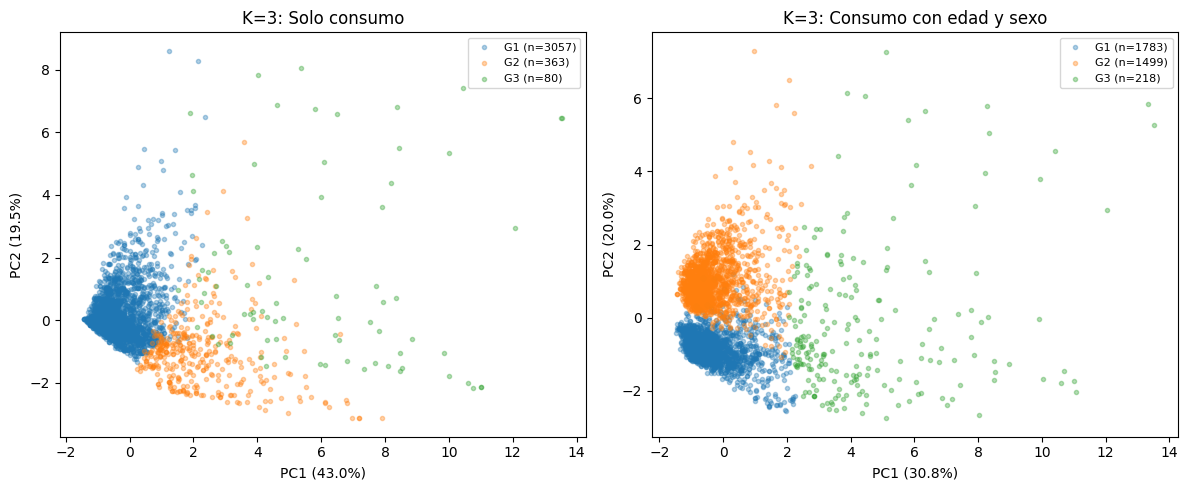

Al agregar edad y sexo, silhouette medido en el mismo espacio de consumo pasa de 0.559 a 0.061. La separación de los hábitos de consumo disminuye según este indicador. En el espacio ampliado, el segundo modelo obtiene silhouette 0.282; esta cifra responde a una distancia que incluye demografía y no equivale a una mejora respecto de consumo solo. Edad y sexo participan por diseño. Se conserva el modelo principal sobre horas y se interpreta este experimento como complemento, sin demostrar causalidad ni grupos naturales.

In [57]:
# Comparación sobre idénticas personas con edad y sexo conocidos.
edad_joint = pd.to_numeric(df_caracterizacion['edad'], errors='coerce')
sexo_joint = df_caracterizacion['Sexo'].astype(str).str.strip().str.lower().map({'femenino': 0, 'masculino': 1})
idx_joint = df_caracterizacion.index[edad_joint.between(12, 18) & sexo_joint.notna()]
horas_joint = X_horas.loc[idx_joint]
z_horas_joint = StandardScaler().fit_transform(horas_joint)
datos_demograficos = pd.DataFrame({'edad': edad_joint.loc[idx_joint], 'sexo_binario': sexo_joint.loc[idx_joint]})
z_demo_joint = StandardScaler().fit_transform(datos_demograficos)
soluciones_joint, filas_joint = {}, []
with threadpool_limits(limits=2):
    for escenario in ["Solo consumo", "Consumo con edad y sexo"]:
        z = z_horas_joint if escenario == "Solo consumo" else np.column_stack([z_horas_joint, z_demo_joint])
        m = KMeans(n_clusters=3, n_init=20, random_state=42, max_iter=500).fit(z)
        orden = horas_joint.groupby(m.labels_).mean().sum(axis=1).sort_values().index
        mapa = {int(g): i+1 for i,g in enumerate(orden)}
        grupos = pd.Series([mapa[int(g)] for g in m.labels_], index=idx_joint, name='grupo')
        soluciones_joint[escenario] = {'z': z, 'grupos': grupos, 'modelo': m}
        filas_joint.append({'modelo': escenario, 'k': 3, 'n': len(idx_joint),
            'silhouette_espacio_propio': silhouette_score(z, grupos),
            'silhouette_solo_consumo': silhouette_score(z_horas_joint, grupos),
            'grupo_menor_n': int(grupos.value_counts().min())})
comparacion_joint = pd.DataFrame(filas_joint)
display(comparacion_joint.round(3))
print('Edad o sexo no disponibles para el experimento:', len(X_horas)-len(idx_joint))
fichas_joint = []
for escenario, s in soluciones_joint.items():
    ficha = horas_joint.copy()
    ficha['edad'] = edad_joint.loc[idx_joint]
    ficha['masculino'] = sexo_joint.loc[idx_joint]
    ficha['grupo'] = s['grupos']
    resumen = ficha.groupby('grupo')[V+['edad', 'masculino']].mean()
    resumen['n'] = ficha.groupby('grupo').size()
    resumen['masculino_pct'] = resumen.pop('masculino')*100
    resumen['femenino_pct'] = 100-resumen['masculino_pct']
    resumen['modelo'] = escenario
    fichas_joint.append(resumen.reset_index())
    print('Modelo:', escenario)
    display(resumen.round(2))
fichas_joint = pd.concat(fichas_joint, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, escenario in zip(axes, soluciones_joint):
    s = soluciones_joint[escenario]
    pca = PCA(n_components=2, random_state=42)
    coord = pca.fit_transform(s['z'])
    for g in [1,2,3]:
        mask = s['grupos'].eq(g).to_numpy()
        ax.scatter(coord[mask,0], coord[mask,1], s=9, alpha=.35, label=f'G{g} (n={mask.sum()})')
    ax.set(title=f'K=3: {escenario}', xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
        ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(R/'pca_k3_demografia.png', dpi=160)
plt.show()
base_j = comparacion_joint.iloc[0]
principal_j = comparacion_joint.loc[comparacion_joint.modelo.eq("Consumo con edad y sexo")].iloc[0]
delta_j = principal_j.silhouette_solo_consumo-base_j.silhouette_solo_consumo
conclusion_joint = (
    f"Al agregar edad y sexo, silhouette medido en el mismo espacio de consumo pasa de "
    f"{base_j.silhouette_solo_consumo:.3f} a {principal_j.silhouette_solo_consumo:.3f}. "
    "La separación de los hábitos de consumo disminuye según este indicador. "
    f"En el espacio ampliado, el segundo modelo obtiene silhouette {principal_j.silhouette_espacio_propio:.3f}; "
    "esta cifra responde a una distancia que incluye demografía y no equivale a una mejora respecto de consumo solo. "
    "Edad y sexo participan por diseño. Se conserva el modelo principal sobre horas y se interpreta este experimento como complemento, sin demostrar causalidad ni grupos naturales.")
display(Markdown(conclusion_joint))
comparacion_joint.to_csv(R/'comparacion_k3_demografia.csv', index=False)
fichas_joint.to_csv(R/'perfiles_k3_demografia.csv', index=False)
pd.DataFrame({escenario: s['grupos'] for escenario,s in soluciones_joint.items()}).to_csv(R/'asignaciones_k3_demografia.csv', index_label='fila_origen')


## 19.1 Interpretación y conclusión del experimento conjunto

La comparación usa **3.500 personas** en ambos modelos; se excluyen los **562 casos sin edad conocida**. El modelo de consumo solo se vuelve a ajustar en esta submuestra para evitar atribuir a la demografía cambios debidos simplemente a utilizar otras personas.

### Características de los tres grupos al incorporar edad y sexo

Esta tabla describe exclusivamente el modelo **consumo con edad y sexo**, ajustado sobre 3.500 personas. Presenta **medias** de horas por actividad; la tabla 17.1 presenta **medianas**, por lo que sus cifras no deben compararse directamente como si fueran el mismo estadístico. Todos los integrantes de este experimento tienen las cinco entradas, edad y sexo disponibles. Los porcentajes de participación se calculan sobre los 3.500 casos; los porcentajes por sexo, dentro de cada grupo.

| Característica | Grupo 1 | Grupo 2 | Grupo 3 |
|---|---:|---:|---:|
| Participantes | 1.783 (50,9 %) | 1.499 (42,8 %) | 218 (6,2 %) |
| Videojuegos: media de horas/día | 0,26 | 1,90 | 3,00 |
| Juegos en celular/tablet: media de horas/día | 1,71 | 1,78 | 10,65 |
| Redes sociales: media de horas/día | 4,11 | 2,74 | 13,72 |
| TV/contenido online: media de horas/día | 2,50 | 2,34 | 11,68 |
| Otras actividades: media de horas/día | 0,76 | 0,82 | 7,53 |
| Edad media (años) | 15,54 | 15,52 | 15,80 |
| Sexo femenino | 100,0 % | 0,3 % | 61,5 % |
| Sexo masculino | 0,0 % | 99,7 % | 38,5 % |
| Mujeres (cantidad) | 1783 | 4 | 134 |
| Varones (cantidad) | 0 | 1495 | 84 |

### Lectura de los perfiles del modelo conjunto

**Grupo 1: perfil femenino con mayor uso medio de redes.** Reúne 1.783 mujeres y ningún varón. Las redes sociales presentan el mayor tiempo medio dentro del perfil (4,11 horas/día), seguidas de TV/contenido online (2,50). Videojuegos tiene una media baja (0,26), sin que ello implique ausencia de uso en todas las integrantes. Su edad media de 15,54 años es casi igual a la del grupo 2.

**Grupo 2: perfil mayoritariamente masculino, con más videojuegos que el grupo 1.** Incluye 1.495 varones y 4 mujeres. La media de videojuegos (1,90 horas/día) es mayor que en el grupo 1, aunque redes sigue siendo la actividad con mayor media dentro de este perfil (2,74), seguida de TV/contenido online (2,34). Por tanto, no corresponde llamarlo un grupo de predominio exclusivo de videojuegos. La comparación de medias de actividades tampoco indica qué porcentaje de personas tiene cada actividad como predominante.

**Grupo 3: consumo elevado en varias actividades, con ambos sexos.** Incluye 134 mujeres (61,5 %) y 84 varones (38,5 %). Presenta medias elevadas en redes (13,72 horas/día), TV/contenido online (11,68), juegos móviles (10,65) y otras actividades (7,53). Es ligeramente mayor en edad media (15,80), pero la diferencia no define una etapa etaria separada. Los tiempos son autorreportados, las actividades pueden solaparse y las medias son sensibles a extremos; no representan un presupuesto de horas exclusivas de una persona típica.

**Qué aporta esta tabla:** al incorporar demografía, la distinción entre los dos grupos grandes se asocia principalmente al sexo, mientras el tercer grupo recoge consumos altos de mujeres y varones. La similitud de edades medias entre los grupos 1 y 2 muestra que no emergen segmentos etarios claramente diferenciados. Estos identificadores no equivalen a los del punto 17: se modificaron las entradas y la población de ajuste. Las diferencias deben interpretarse junto con silhouette, que muestra una menor separación por consumo, y no como evidencia de que el modelo conjunto haya mejorado los perfiles principales.

Al incorporar edad y sexo aparecen un grupo de **1.783 personas, 100 % femenino**, otro de **1.499, 99,7 % masculino**, y un tercero de **218 personas** con consumos altos. Las edades medias de los primeros dos grupos son casi iguales (15,54 y 15,52), por lo que la separación demográfica observada corresponde principalmente al sexo. El tercer grupo incluye aproximadamente 38,5 % de varones y 61,5 % de mujeres.

Silhouette del modelo conjunto en sus siete dimensiones es **0,282**. Sin embargo, al evaluar sus etiquetas en el espacio común de las cinco actividades, alcanza **0,061**, frente a **0,559** del modelo de consumo solo. Por tanto, **agregar edad y sexo no mejora la separación por hábitos de consumo según este indicador**. Cambia el criterio de semejanza y produce grupos más asociados al sexo, sin conseguir perfiles de consumo mejor diferenciados.

La PCA representa visualmente este cambio, pero no lo valida de manera independiente. Una separación por sexo es esperable cuando esa variable participa en la distancia y no constituye una asociación descubierta de forma independiente.

Se mantiene K=3 sobre horas como modelo principal y el modelo conjunto como complemento. Para describir diferencias específicas de actividades entre edades y sexos, las tablas del punto 18 siguen siendo más directas. No se concluye que edad y sexo carezcan de relación con el consumo, sino que incluirlos de esta manera no mejora la separación de consumo para K=3 en esta muestra.


# 20. Exportación y reproducibilidad

Los resultados vigentes se guardan en `resultados_proyecto_k3/`: modelo principal, asignaciones, medias y medianas de consumo, exploración de K, auditorías, caracterización y experimento demográfico. Para inferencia se requieren las cinco actividades en el orden documentado, finitas, entre 0 y 24 horas y sin faltantes. El modelo serializado incluye el escalador y K-Means. Se registran dependencias, semillas y hash del Excel.


In [58]:
for nombre, s in {"referencia_original": referencia}.items():
    carpeta = R / nombre
    carpeta.mkdir(exist_ok=True)
    for archivo, tabla in {"resumen": s["resumen"], "medias_horas": s["medias"], "medianas_horas": s["medianas"]}.items():
        tabla.to_csv(carpeta / f"{archivo}.csv", index_label="grupo")
    pd.DataFrame({"grupo": s["grupos"], "silhouette": s["silhouette"]}).to_csv(carpeta/"asignaciones.csv", index_label="fila_origen")
    joblib.dump({"pipeline": s["pipeline"], "variables": V, "mapa_grupos": s["mapa"],
        "k": 3, "representacion": s["nombre"], "requiere_total_positivo": nombre != "referencia_original",
        "dominio_horas": [0, 24]}, carpeta/"modelo_k3.joblib")
for archivo, tabla in {
    "auditoria_conversion": auditoria_conversion, "discrepancias_conversion": detalle_conversion,
    "comparacion_k_original": comparacion_k,
    "caracterizacion_completa": caracterizacion_revision,
    "categoricas_completas": categoricas_revision, "auditoria_auxiliares": auditoria_aux_revision,
    "rho_demografia": rho_demo,
}.items():
    tabla.to_csv(R/f"{archivo}.csv", index=False)
banderas_extremos.to_csv(R/"banderas_extremos.csv", index_label="fila_origen")
predominio_demo.to_csv(R/"predominio_demografico.csv")
uso_demo.to_csv(R/"participacion_demografica.csv")
from importlib.metadata import version
import shutil
paquetes = ["numpy", "pandas", "matplotlib", "scikit-learn", "scipy", "openpyxl", "ipython", "joblib", "threadpoolctl", "nbformat"]
(R/"requirements.txt").write_text("\n".join(f"{p}=={version(p)}" for p in paquetes)+"\n", encoding="utf-8")
(R/"configuracion.json").write_text(json.dumps({"k_referencia": 3, "n_completo": len(X_horas),
    "semilla": 42, "n_init": 20, "rango_k": [1, 10], "modelos_demograficos": ["Solo consumo", "Consumo con edad y sexo"],
    "sha256_excel": hashlib.sha256(Path(path).read_bytes()).hexdigest()}, ensure_ascii=False, indent=2), encoding="utf-8")
print("Resultados vigentes:", R.resolve())


Resultados vigentes: /content/resultados_proyecto_k3


# 21. Conclusión final del proyecto

El proyecto permitió aplicar aprendizaje automático no supervisado al estudio del consumo digital en adolescentes. Como se planteó en el punto 14, se eligió **K-Means** para explorar si las similitudes en el uso de pantallas permitían identificar grupos diferenciados. El EDA, la limpieza, la selección de variables, el entrenamiento y la interpretación se desarrollaron de manera coherente con ese objetivo.

### Balance del proyecto y respuesta al objetivo inicial

La exploración mediante codo y silhouette mostró que **K=2 obtiene la mayor puntuación global (0,638)** en el rango evaluado. Se mantuvo **K=3 (0,556)** como una decisión descriptiva que ofrece más detalle y una puntuación superior a K=4 y K=5, sin presentarlo como un óptimo estadístico demostrado. La PCA permitió visualizar los resultados, pero el clustering se entrenó sobre las cinco entradas estandarizadas y no sobre la proyección.

En relación con la pregunta del punto 14, **se logró identificar y describir heterogeneidad de consumo, pero no confirmar tres grupos naturales claramente separados**. Los silhouette medios de los grupos 2 y 3 fueron aproximadamente −0,019 y 0,046, con una proporción elevada de asignaciones negativas. Por tanto, el promedio global no representa por igual la calidad de todos los perfiles. La solución está fuertemente vinculada a la intensidad declarada y a los valores extremos, y sus fronteras deben considerarse débiles en los grupos de mayor consumo.

El aporte del trabajo es una segmentación interpretable que organiza patrones de uso y permite relacionarlos descriptivamente con características externas. Su alcance se limita a la muestra analizada: 562 participantes tienen edad desconocida, las duraciones son autorreportadas, las actividades pueden solaparse y la información académica es parcial. No se evaluó estabilidad ni validación en una cohorte independiente. Como continuación sería pertinente revisar el instrumento y los consumos extremos y contrastar los perfiles con nuevos datos.

**K=3 se conserva como una herramienta descriptiva útil para comunicar lo encontrado, no como una clasificación definitiva de adolescentes.** El complemento demográfico amplía la interpretación, mientras que el modelo basado en las variables originales mantiene la conexión más directa con el objetivo de describir perfiles de consumo digital.

### Qué se obtuvo con K=3 sobre las variables originales

El modelo principal utilizó **4.062 registros y cinco variables originales de horas por actividad**, validadas y estandarizadas. Se conservaron los consumos superiores a 12 horas para no excluir de antemano usos intensivos; esta decisión preservó información relevante, aunque también mantuvo respuestas extremas que requieren una interpretación cautelosa. Las entradas estaban completas, por lo que no fue necesario imputarlas, y los seis casos de consumo totalmente nulo permanecieron incluidos.

La solución permitió describir tres perfiles:

- **Menor intensidad relativa:** 3.545 participantes (87,3 %). Presenta las menores medianas en las cinco actividades, con mayor presencia de redes y contenido audiovisual en su patrón central. Incluye mujeres y varones y puede contener diversidad interna que esta partición no distingue.
- **Uso elevado de redes y juegos móviles:** 431 participantes (10,6 %). Se diferencia por medianas mayores en redes, juegos en celular/tablet y TV/contenido online. Tiene mayor proporción femenina, sin ser un perfil exclusivo de mujeres.
- **Consumo múltiple extremo declarado:** 86 participantes (2,1 %). Concentra tiempos altos en varias actividades, especialmente en la categoría amplia de otras actividades. Incluye ambos sexos, con ligera mayoría masculina. La denominación declarado reconoce que la consistencia de las conversiones no demuestra la exactitud del autorreporte.

La caracterización posterior mostró menor sueño medio entre semana y mayor puntaje de somnolencia en los perfiles de consumo más intenso. Estas asociaciones no permiten concluir que el consumo de pantallas haya causado esas diferencias. Las notas disponibles tuvieron una cobertura limitada, especialmente en el tercer grupo, con solo ocho promedios; no permiten caracterizar el rendimiento académico de todos sus integrantes.

### Aporte del complemento demográfico

**Agregar edad y sexo a K=3 no aportó una mejora en la separación de los perfiles de consumo respecto de utilizar solo las variables originales.** Sin embargo, no corresponde afirmar que produjo pocas diferencias en la composición de los grupos: dos de los nuevos perfiles quedaron casi separados por sexo y el tercero concentró consumos altos. Las edades medias de los dos grupos grandes fueron muy similares, por lo que tampoco se identificaron etapas etarias claramente diferenciadas.

La comparación se realizó sobre las mismas 3.500 personas con información demográfica disponible. Silhouette, calculado en el espacio común de consumo, pasó de **0,559** para consumo solo a **0,061** al incorporar edad y sexo. El segundo modelo obtuvo **0,282** en su espacio ampliado, pero ese indicador responde a una distancia diferente y no representa una mejora directa sobre el modelo original. Se concluye que la demografía cambió el criterio de agrupamiento sin mejorar la separación por hábitos de consumo en este experimento. Por ello se mantuvo como complemento y no sustituyó el análisis principal.

Las comparaciones descriptivas por edad y sexo sí aportaron información específica: entre los varones, la participación en videojuegos fue del 72,8 % en el segmento de 12–15 años y del 62,2 % en el de 16–18. El predominio de redes fue mayor en el segmento de mayor edad para ambos sexos. Estos patrones describen diferencias entre participantes y no prueban cambios individuales con la edad ni relaciones causales.


# 22. Decisiones metodológicas y justificación del trabajo

## Objetivo que orientó las decisiones

Buscamos **identificar y caracterizar perfiles de adolescentes según distintas combinaciones de actividades digitales y sus intensidades de consumo**, sin imponer categorías previas. Nuestro objetivo es exploratorio y descriptivo: no pretendemos predecir sueño o rendimiento académico ni establecer causalidad. No imponer etiquetas previas no significa que la partición sea independiente de nuestras decisiones: las entradas, el escalado, K y la distancia determinan qué similitudes utiliza K-Means.

## Decisiones y justificativos

| N.º | Decisión del equipo | Justificación |
|---|---|---|
| 1 | **Aprendizaje no supervisado (clustering).** | No contamos con etiquetas previas de perfiles; queremos que las similitudes entre las actividades permitan explorar agrupamientos. |
| 2 | **EDA antes de entrenar.** | Debíamos entender distribuciones, tipos, nulos, duplicados, valores especiales y relaciones entre variables antes de definir reglas de limpieza y el modelo. |
| 3 | **Auditar variables originales y `trimmed`.** | El tratamiento del estudio original podía responder a otros objetivos. Verificamos conversiones, umbrales y discrepancias en lugar de adoptar automáticamente sus transformaciones. |
| 4 | **Utilizar horas originales de actividades, no las versiones `trimmed`.** | Queríamos conservar posibles consumos intensivos; el umbral de 12 horas por actividad podía excluir respuestas relevantes para explorar la heterogeneidad. **Conservar un dato no significa validar su exactitud.** |
| 5 | **Validación de dominio: 0 a 24 horas por actividad.** | Se convierten en faltantes los valores negativos, superiores a 24, infinitos o no interpretables como números. Estar dentro de 0–24 es un control de dominio, no una prueba de plausibilidad; las respuestas altas se señalan sin declararlas exactas. |
| 6 | **Usar IQR para identificar extremos, no para eliminarlos.** | Una observación rara no necesariamente es errónea. Eliminar extremos de forma automática podría sesgar la segmentación; aceptamos como limitación que K-Means es sensible a ellos. |
| 7 | **No interpretar sumas superiores a 24 horas como exclusión automática.** | Las actividades declaradas pueden superponerse. La suma no equivale necesariamente a tiempo exclusivo del día; igualmente se informa como alerta de plausibilidad. |
| 8 | **Tratamiento de faltantes según la función de la variable.** | Para clustering exigimos datos válidos en las cinco entradas, sin imputar ni sustituir faltantes por cero. Para caracterización retenemos faltantes e informamos los casos válidos, sin excluir observaciones por falta de notas o sueño. |
| 9 | **No eliminar registros solo por un código repetido.** | Un identificador compartido no prueba que las filas sean duplicadas ni que correspondan a una misma persona. Se distingue repetición de códigos de duplicación de registros; los identificadores se reservan para trazabilidad, sin usarlos como predictores. La ausencia de duplicados exactos tampoco garantiza ausencia de respuestas repetidas no idénticas. |
| 10 | **Conservar 562 participantes sin edad individual.** | La edad no interviene en las cinco entradas del modelo principal, por lo que su ausencia no impide calcular la segmentación de consumo. Se excluyeron 53 casos con edad informada fuera de 12–18 y se conservaron 562 sin edad, sin imputarla. **No puede confirmarse que estos últimos pertenezcan al rango etario objetivo**: la selección del estudio de origen no reemplaza una comprobación individual. Esto amplía la cobertura de consumo a cambio de incertidumbre poblacional. Los análisis por edad y el modelo demográfico se limitan a 3.500 casos con edad conocida. |
| 11 | **Seleccionar cinco horas originales: videojuegos, juegos móviles, redes sociales, TV/online y otras actividades.** | Son variables cuantitativas directamente ligadas al objetivo y permiten explorar niveles y combinaciones de uso. La matriz principal tiene 4.062 filas y cinco entradas completas tras la validación, sin pérdida adicional por faltantes; la base de caracterización contiene otras columnas que no ingresan al modelo. |
| 12 | **Excluir tiempo total y porcentajes como entradas simultáneas.** | Derivan de las mismas cinco actividades. Sumarlos a sus componentes duplicaría información o introduciría dependencia composicional, alterando el peso de ciertas dimensiones. |
| 13 | **Reservar edad, sexo, grado, sueño, PDSS y notas para caracterización.** | Queríamos que los grupos se formaran por consumo digital y luego describir diferencias externas, evitando definir los clusters mediante las mismas características que después se analizarían. |
| 14 | **Usar frecuencias de dispositivos y contexto de uso como variables auxiliares.** | Aportan información interpretativa, pero introducirlas en el modelo principal cambiaría la pregunta y mezclaría intensidad por actividad con hábitos contextuales. Miden días de uso en la hora previa a dormir, no frecuencia general durante el día. Se validan días enteros entre 0 y 7; en esta familia el resultado coincide con las versiones trimmed. Los indicadores de contexto corresponden a categorías específicas verificadas y su cero no equivale siempre a ausencia de uso. |
| 15 | **Aplicar `StandardScaler` a las cinco entradas.** | Aunque todas se expresan en horas, presentan dispersiones diferentes; estandarizar permite que una actividad no domine solo por tener mayor variabilidad original. No elimina asimetría ni efecto de extremos. |
| 16 | **Elegir K-Means como modelo de referencia.** | Permite obtener centroides y asignaciones interpretables con cinco variables cuantitativas y un costo adecuado. Minimiza distancias euclidianas cuadradas y favorece particiones compactas: es sensible a escala y extremos y genera K grupos aunque no existan categorías naturales. Jerárquico, DBSCAN y GMM se mantienen como alternativas consideradas, sin entrenamiento en la versión actual. |
| 17 | **Explorar varios valores de K con inercia/codo y silhouette.** | Se exploró K=1–10 sobre la misma matriz. La inercia disminuye al aumentar K por construcción; el codo puede ser ambiguo. Silhouette se calcula desde K=2, porque no está definido para una única agrupación. Ninguno de estos indicadores constituye por sí solo una prueba de grupos naturales. |
| 18 | **Conservar K=3 aunque K=2 tenga mejor silhouette.** | K=2 logró **0,638**, pero buscábamos explorar más que una división general entre menor y mayor consumo. K=3 obtuvo **0,556** y permitió mayor detalle; K=4 bajó a **0,447**. Es una **elección descriptiva y exploratoria**, no el óptimo estadístico demostrado. |
| 19 | **Fijar semilla y realizar múltiples inicializaciones de K-Means.** | Se utiliza semilla 42, 20 inicializaciones y máximo 500 iteraciones. Las múltiples inicializaciones reducen el riesgo de una solución desfavorable por los centroides iniciales y la semilla permite reproducir esta ejecución. No demuestran óptimo global, estabilidad poblacional ni generalización a nuevos datos. |
| 20 | **Utilizar PCA para visualizar, no para entrenar.** | La proyección a dos dimensiones facilita interpretar patrones y superposiciones; las asignaciones se calcularon con las cinco variables estandarizadas originales. |
| 21 | **Evaluar silhouette global y por cluster.** | El promedio puede ocultar grupos mal separados. Los grupos 2 y 3 presentan silhouette medio aproximado de **−0,019** y **0,046**; reconocemos que sus fronteras son débiles. |
| 22 | **Interpretar perfiles con medianas de horas.** | Las distribuciones son asimétricas y tienen extremos; las medianas permiten una descripción menos sensible a extremos; no corrigen la influencia de esos valores durante el entrenamiento. El entrenamiento de K-Means, en cambio, se basa en centroides de medias en el espacio estandarizado. La tabla del modelo conjunto informa medias, explicitadas para no compararlas como si fueran medianas. |
| 23 | **Caracterizar externamente con demografía, sueño, somnolencia y notas.** | Queremos explorar diferencias entre perfiles sin confundir asociaciones descriptivas con efectos causales. Mostramos denominadores por variable, especialmente por la alta ausencia de notas. |
| 24 | **Probar un modelo complementario con edad y sexo.** | Se compararon consumo solo y consumo con edad y sexo, con K=3 en los mismos **3.500 casos**, estandarizando las entradas y sin ponderaciones adicionales. Silhouette en el espacio común de consumo cayó de **0,559** a **0,061**. El espacio ampliado obtuvo 0,282, pero usa otra distancia. Dos grupos quedaron casi separados por sexo; incluir demografía cambió el criterio sin mejorar la separación de consumo según el indicador común. Se conservó como complemento. No implica que edad y sexo carezcan de asociación con los hábitos. |
| 25 | **Exportar bases procesadas, asignaciones, auditorías y parámetros.** | La trazabilidad y reproducibilidad permiten revisar desde las reglas de limpieza hasta la interpretación; conservar resultados facilita controlar decisiones y reutilizar el análisis. |

## Resultado que defendemos

La partición **K=3** describió **4.062 participantes**:

- **Grupo 1:** 3.545 (87,3 %), menor intensidad relativa.
- **Grupo 2:** 431 (10,6 %), uso elevado especialmente de redes sociales y juegos móviles.
- **Grupo 3:** 86 (2,1 %), consumo múltiple extremo declarado.

**Interpretación esencial:** los resultados permiten describir heterogeneidad, pero **no prueban tres categorías naturales claramente separadas**. La segmentación parece reflejar principalmente intensidad declarada y valores extremos, más que tres preferencias de actividad nítidamente independientes.

## Límites reconocidos y continuidad posible

Las siguientes son limitaciones o propuestas para otra etapa, **no análisis ejecutados en la versión actual**:


1. **Cantidad de grupos:** K=3 es una elección descriptiva, aunque K=2 tiene mayor silhouette. La baja calidad interna de los grupos 2 y 3 impide afirmar tres categorías naturales bien delimitadas.
2. **Población y cobertura:** los 562 casos sin edad agregan incertidumbre sobre pertenencia al rango objetivo. Las notas presentan alta ausencia y solo ocho promedios disponibles en el grupo extremo; no permiten generalizaciones académicas por perfil.


## Resumen

> Para este proyecto tomamos decisiones trazables para explorar la diversidad del consumo digital adolescente y valorar críticamente la segmentación obtenida. Conservamos las actividades originales para estudiar intensidades y combinaciones, evaluamos diferentes particiones y elegimos K=3 como una herramienta descriptiva, reconociendo que K=2 tiene mejor separación. El principal aporte es una caracterización interpretable de la muestra y una evaluación crítica de sus límites, no la afirmación de que existen tres tipos universales de adolescentes.
